In [1]:
import torch

if torch.backends.mps.is_available():
    device = torch.device("mps")  # Apple GPU
else:
    device = torch.device("cpu")

print("Training device:", device)

Training device: mps


In [2]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Convert images to tensors: arrays PyTorch can process.
transform = transforms.ToTensor()

full_train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(full_train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", full_train_dataset.classes)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


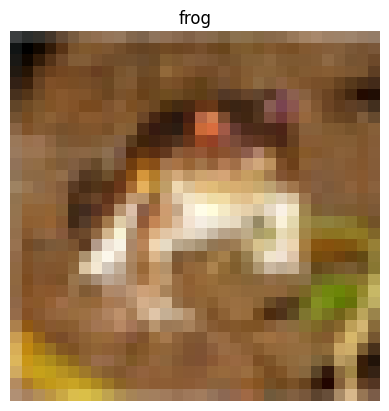

Image shape: torch.Size([3, 32, 32])
Number of pixel values: 3072
Pixel value range: 0.0 1.0


In [3]:
image, label = full_train_dataset[0]

plt.imshow(image.permute(1, 2, 0))
plt.title(full_train_dataset.classes[label])
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Number of pixel values:", image.numel())
print("Pixel value range:", image.min().item(), image.max().item())

In [4]:
from torch.utils.data import random_split, DataLoader

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Training images: 45000
Validation images: 5000
Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])


In [5]:
import torch.nn as nn

class CNNTrunk(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            # Input: 3 × 32 × 32
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Output: 16 × 16 × 16

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # Output: 32 × 8 × 8

            nn.Flatten()
            # Output: 2,048 numbers per image
        )

    def forward(self, x):
        return self.layers(x)


trunk = CNNTrunk().to(device)

images, labels = next(iter(train_loader))

with torch.no_grad():
    features = trunk(images.to(device))

print("Image batch shape:", images.shape)
print("Feature batch shape:", features.shape)

Image batch shape: torch.Size([128, 3, 32, 32])
Feature batch shape: torch.Size([128, 2048])


In [8]:
class RootNode(nn.Module):
    def __init__(self, hidden_width=64):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(2048, hidden_width),
            nn.ReLU(),
            nn.Linear(hidden_width, 10)
        )

    def forward(self, features):
        return self.layers(features)


root_node = RootNode().to(device)

# The existing trunk and the new root form one model.
model = nn.Sequential(trunk, root_node).to(device)

with torch.no_grad():
    scores = model(images.to(device))

print("Output shape:", scores.shape)
print("First image's scores:", scores[0].cpu())

Output shape: torch.Size([128, 10])
First image's scores: tensor([-0.0157, -0.1090, -0.0589,  0.0367, -0.0742, -0.0700,  0.0609,  0.0654,
         0.0338,  0.0404])


In [9]:
import time

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history = []

def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            scores = model(images)
            loss = criterion(scores, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


# Start with 5 epochs to measure learning and speed.
for epoch in range(5):
    start = time.perf_counter()
    model.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        scores = model(images)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()

    # Evaluate the final weights on both sets.
    train_loss, train_acc = evaluate(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch + 1}: "
        f"train loss={train_loss:.3f}, accuracy={train_acc:.2f}% | "
        f"val loss={val_loss:.3f}, accuracy={val_acc:.2f}% | "
        f"time={time.perf_counter() - start:.1f}s"
    )

Epoch 1: train loss=1.521, accuracy=45.06% | val loss=1.525, accuracy=45.48% | time=4.9s
Epoch 2: train loss=1.386, accuracy=50.77% | val loss=1.406, accuracy=50.00% | time=3.5s
Epoch 3: train loss=1.254, accuracy=55.38% | val loss=1.291, accuracy=54.26% | time=3.4s
Epoch 4: train loss=1.161, accuracy=58.82% | val loss=1.204, accuracy=57.28% | time=3.5s
Epoch 5: train loss=1.101, accuracy=60.87% | val loss=1.157, accuracy=58.70% | time=3.6s


In [10]:
root_node = RootNode().to(device)
model = nn.Sequential(trunk, root_node).to(device)

print(model)

Sequential(
  (0): CNNTrunk(
    (layers): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Flatten(start_dim=1, end_dim=-1)
    )
  )
  (1): RootNode(
    (layers): Sequential(
      (0): Linear(in_features=2048, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=10, bias=True)
    )
  )
)


In [11]:
# Preserve the mixed-run history for debugging.
previous_history = [entry.copy() for entry in history]

# Attach a fresh optimizer to the CURRENT model.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Start a separate history for the corrected training run.
history = []

model_ids = {
    id(p) for p in model.parameters()
    if p.requires_grad
}

optimizer_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

assert model_ids == optimizer_ids
print("Optimizer matches model: True")

Epoch 6: train loss=2.280, accuracy=17.65% | val loss=2.278, accuracy=17.94% | time=3.3s
Epoch 7: train loss=2.262, accuracy=20.56% | val loss=2.260, accuracy=21.12% | time=4.0s
Epoch 8: train loss=2.241, accuracy=23.00% | val loss=2.238, accuracy=23.90% | time=4.0s
Epoch 9: train loss=2.215, accuracy=22.56% | val loss=2.211, accuracy=22.98% | time=4.2s
Epoch 10: train loss=2.182, accuracy=22.84% | val loss=2.177, accuracy=23.16% | time=4.4s
Epoch 11: train loss=2.145, accuracy=24.18% | val loss=2.141, accuracy=24.58% | time=3.4s
Epoch 12: train loss=2.107, accuracy=25.10% | val loss=2.103, accuracy=25.70% | time=3.8s
Epoch 13: train loss=2.069, accuracy=26.17% | val loss=2.066, accuracy=26.74% | time=4.1s
Epoch 14: train loss=2.033, accuracy=27.72% | val loss=2.031, accuracy=28.22% | time=4.4s
Epoch 15: train loss=1.995, accuracy=29.12% | val loss=1.995, accuracy=29.20% | time=3.7s
Epoch 16: train loss=1.958, accuracy=30.64% | val loss=1.957, accuracy=30.76% | time=3.6s
Epoch 17: trai

In [12]:
 # Check that the optimizer updates the current model.
model_ids = {
    id(p) for p in model.parameters()
    if p.requires_grad
}

optimizer_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

print("Optimizer matches model:", model_ids == optimizer_ids)
print("Learning rates:", [
    group["lr"] for group in optimizer.param_groups
])

print("\nCurrent model:")
print(model)

print("\nFirst 10 history entries:")
for entry in history[:10]:
    print(entry)

print("\nDataset sizes:")
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))

Optimizer matches model: False
Learning rates: [0.001]

Current model:
Sequential(
  (0): CNNTrunk(
    (layers): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Flatten(start_dim=1, end_dim=-1)
    )
  )
  (1): RootNode(
    (layers): Sequential(
      (0): Linear(in_features=2048, out_features=64, bias=True)
      (1): ReLU()
      (2): Linear(in_features=64, out_features=10, bias=True)
    )
  )
)

First 10 history entries:
{'epoch': 1, 'train_loss': 1.5214931257459852, 'train_accuracy': 45.062222222222225, 'val_loss': 1.5250696941375732, 'val_accuracy': 45.48}
{'epoch': 2, 'train_loss': 1.3859775843302409, 'train_accuracy': 50.77333333333333, 'val_loss

In [13]:
# Preserve the mixed-run history for debugging.
previous_history = [entry.copy() for entry in history]

# Attach a fresh optimizer to the CURRENT model.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Start a separate history for the corrected training run.
history = []

model_ids = {
    id(p) for p in model.parameters()
    if p.requires_grad
}

optimizer_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

assert model_ids == optimizer_ids
print("Optimizer matches model: True")

Optimizer matches model: True


In [14]:
for _ in range(25):
    epoch_number = len(history) + 1
    start = time.perf_counter()

    model.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        scores = model(images)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()

    train_loss, train_acc = evaluate(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    history.append({
        "epoch": epoch_number,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    # Save progress after every epoch.
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "history": history
    }, "cifar_root_checkpoint.pt")

    print(
        f"Epoch {epoch_number}: "
        f"train loss={train_loss:.3f}, accuracy={train_acc:.2f}% | "
        f"val loss={val_loss:.3f}, accuracy={val_acc:.2f}% | "
        f"time={time.perf_counter() - start:.1f}s"
    )

Epoch 1: train loss=1.466, accuracy=45.22% | val loss=1.489, accuracy=44.58% | time=3.5s
Epoch 2: train loss=1.337, accuracy=51.31% | val loss=1.372, accuracy=50.36% | time=3.8s
Epoch 3: train loss=1.342, accuracy=50.91% | val loss=1.373, accuracy=49.78% | time=3.5s
Epoch 4: train loss=1.279, accuracy=52.86% | val loss=1.338, accuracy=51.32% | time=3.6s
Epoch 5: train loss=1.217, accuracy=55.79% | val loss=1.273, accuracy=54.52% | time=3.6s
Epoch 6: train loss=1.148, accuracy=58.63% | val loss=1.211, accuracy=56.66% | time=3.5s
Epoch 7: train loss=1.142, accuracy=58.82% | val loss=1.212, accuracy=56.08% | time=3.5s
Epoch 8: train loss=1.120, accuracy=59.85% | val loss=1.205, accuracy=57.42% | time=4.0s
Epoch 9: train loss=1.090, accuracy=61.10% | val loss=1.184, accuracy=56.96% | time=3.7s
Epoch 10: train loss=1.087, accuracy=60.93% | val loss=1.177, accuracy=57.76% | time=4.1s
Epoch 11: train loss=1.056, accuracy=62.02% | val loss=1.152, accuracy=58.68% | time=3.7s
Epoch 12: train los

In [15]:
# Keep the learned trunk weights fixed.
trunk.eval()

for parameter in trunk.parameters():
    parameter.requires_grad_(False)


def extract_features(dataset):
    # Fixed order keeps each feature vector aligned with its label.
    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0
    )

    feature_batches = []
    label_batches = []

    with torch.no_grad():
        for images, labels in loader:
            features = trunk(images.to(device))

            feature_batches.append(features.cpu())
            label_batches.append(labels.cpu())

    return (
        torch.cat(feature_batches),
        torch.cat(label_batches)
    )


X_train, y_train = extract_features(train_dataset)
X_val, y_val = extract_features(val_dataset)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation features:", X_val.shape)

torch.save({
    "trunk_state": trunk.state_dict(),
    "root_state": root_node.state_dict(),
    "train_indices": list(train_dataset.indices),
    "val_indices": list(val_dataset.indices),
    "history": history
}, "cifar_baseline_before_tree.pt")

Training features: torch.Size([45000, 2048])
Training labels: torch.Size([45000])
Validation features: torch.Size([5000, 2048])


In [16]:
from torch.utils.data import DataLoader

# Freeze the learned CNN trunk.
trunk.eval()

for parameter in trunk.parameters():
    parameter.requires_grad_(False)


def extract_features(dataset):
    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=0
    )

    feature_batches = []
    label_batches = []

    with torch.no_grad():
        for images, labels in loader:
            features = trunk(images.to(device))

            feature_batches.append(features.cpu())
            label_batches.append(labels.cpu())

    return (
        torch.cat(feature_batches),
        torch.cat(label_batches)
    )


X_train, y_train = extract_features(train_dataset)
X_val, y_val = extract_features(val_dataset)

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation features:", X_val.shape)

# Save the baseline weights and dataset split.
torch.save({
    "trunk_state": trunk.state_dict(),
    "root_state": root_node.state_dict(),
    "train_indices": list(train_dataset.indices),
    "val_indices": list(val_dataset.indices),
    "history": history
}, "cifar_baseline_before_tree.pt")

Training features: torch.Size([45000, 2048])
Training labels: torch.Size([45000])
Validation features: torch.Size([5000, 2048])


In [17]:
from torch.utils.data import TensorDataset, DataLoader

cat_class = full_train_dataset.classes.index("cat")

# Convert ten-class labels into cat-versus-rest labels.
cat_train_targets = (y_train == cat_class).float()
cat_val_targets = (y_val == cat_class).float()


class BinaryNode(nn.Module):
    def __init__(self, input_dim=2048, hidden_width=64):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_width),
            nn.ReLU(),
            nn.Linear(hidden_width, 1)
        )

    def forward(self, features):
        return self.layers(features).squeeze(-1)


cat_root = BinaryNode().to(device)

cat_loader = DataLoader(
    TensorDataset(X_train, cat_train_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

# Cats are approximately 10% of the dataset.
# Give positive examples more weight during training.
positive_count = cat_train_targets.sum()
negative_count = len(cat_train_targets) - positive_count

positive_weight = (
    negative_count / positive_count
).reshape(1).to(device)

binary_loss = nn.BCEWithLogitsLoss(
    pos_weight=positive_weight
)

cat_optimizer = torch.optim.Adam(
    cat_root.parameters(),
    lr=0.001
)

print("Cat examples:", int(positive_count.item()))
print("Other examples:", int(negative_count.item()))

Cat examples: 4529
Other examples: 40471


In [18]:
def binary_metrics(node, features, targets):
    node.eval()
    predictions = []

    with torch.no_grad():
        for batch in features.split(512):
            scores = node(batch.to(device))
            predictions.append((scores >= 0).cpu())

    predicted = torch.cat(predictions)
    actual = targets.bool()

    accuracy = (predicted == actual).float().mean().item()

    # Recall for each of the two classes.
    cat_recall = predicted[actual].float().mean().item()
    other_recall = (~predicted[~actual]).float().mean().item()

    balanced_accuracy = (cat_recall + other_recall) / 2

    return accuracy, balanced_accuracy, predicted


for epoch in range(10):
    cat_root.train()

    for features, targets in cat_loader:
        features = features.to(device)
        targets = targets.to(device)

        cat_optimizer.zero_grad()

        scores = cat_root(features)
        loss = binary_loss(scores, targets)

        loss.backward()
        cat_optimizer.step()

    train_acc, train_balanced, _ = binary_metrics(
        cat_root, X_train, cat_train_targets
    )

    val_acc, val_balanced, _ = binary_metrics(
        cat_root, X_val, cat_val_targets
    )

    print(
        f"Epoch {epoch + 1}: "
        f"train accuracy={100 * train_acc:.2f}%, "
        f"balanced={100 * train_balanced:.2f}% | "
        f"val accuracy={100 * val_acc:.2f}%, "
        f"balanced={100 * val_balanced:.2f}%"
    )

Epoch 1: train accuracy=61.21%, balanced=75.95% | val accuracy=60.62%, balanced=74.08%
Epoch 2: train accuracy=78.81%, balanced=80.55% | val accuracy=78.62%, balanced=78.02%
Epoch 3: train accuracy=79.30%, balanced=82.34% | val accuracy=78.30%, balanced=79.27%
Epoch 4: train accuracy=86.74%, balanced=80.39% | val accuracy=85.64%, balanced=76.09%
Epoch 5: train accuracy=84.18%, balanced=83.58% | val accuracy=82.90%, balanced=78.67%
Epoch 6: train accuracy=80.85%, balanced=85.09% | val accuracy=79.26%, balanced=78.47%
Epoch 7: train accuracy=72.54%, balanced=83.36% | val accuracy=71.62%, balanced=78.82%
Epoch 8: train accuracy=82.69%, balanced=86.43% | val accuracy=80.34%, balanced=79.26%
Epoch 9: train accuracy=73.88%, balanced=84.44% | val accuracy=72.38%, balanced=79.24%
Epoch 10: train accuracy=83.17%, balanced=87.96% | val accuracy=80.52%, balanced=79.26%


In [19]:
_, _, predicted = binary_metrics(
    cat_root, X_train, cat_train_targets
)

actual = cat_train_targets.bool()

C1 = (~predicted) & (~actual)  # Correct other
C2 = predicted & actual       # Correct cat
C3 = (~predicted) & actual    # Missed cat
C4 = predicted & (~actual)    # Other mistaken for cat

for name, mask in [
    ("C1", C1),
    ("C2", C2),
    ("C3", C3),
    ("C4", C4)
]:
    print(name, ":", mask.sum().item())

torch.save(
    cat_root.state_dict(),
    "cifar_cat_binary_root.pt"
)

C1 : 33172
C2 : 4255
C3 : 274
C4 : 7299


In [20]:
def train_child(features, targets, epochs=15):
    child = BinaryNode(hidden_width=32).to(device)

    positive_count = targets.sum().item()
    negative_count = len(targets) - positive_count

    # Handle a task containing only one target class.
    if positive_count == 0 or negative_count == 0:
        return None, float(positive_count > 0)

    loader = DataLoader(
        TensorDataset(features, targets),
        batch_size=256,
        shuffle=True,
        num_workers=0
    )

    positive_weight = torch.tensor(
        [negative_count / positive_count],
        dtype=torch.float32,
        device=device
    )

    loss_function = nn.BCEWithLogitsLoss(
        pos_weight=positive_weight
    )

    optimizer = torch.optim.Adam(
        child.parameters(),
        lr=0.001
    )

    for epoch in range(epochs):
        child.train()

        for batch_features, batch_targets in loader:
            batch_features = batch_features.to(device)
            batch_targets = batch_targets.to(device)

            optimizer.zero_grad()
            scores = child(batch_features)
            loss = loss_function(scores, batch_targets)
            loss.backward()
            optimizer.step()

        if (epoch + 1) % 5 == 0:
            accuracy, balanced, _ = binary_metrics(
                child, features, targets
            )

            print(
                f"Epoch {epoch + 1}: "
                f"accuracy={100 * accuracy:.2f}% | "
                f"balanced={100 * balanced:.2f}%"
            )

    return child, None


# Child A:
# Target 1 for C3, target 0 for C1 and C4, ignore C2.
A_mask = ~C2
A_targets = C3[A_mask].float()

# Child B:
# Target 1 for C4, target 0 for C2 and C3, ignore C1.
B_mask = ~C1
B_targets = C4[B_mask].float()


print("TRAINING CHILD A")
child_A, constant_A = train_child(
    X_train[A_mask],
    A_targets
)

print("\nTRAINING CHILD B")
child_B, constant_B = train_child(
    X_train[B_mask],
    B_targets
)

TRAINING CHILD A
Epoch 5: accuracy=60.15% | balanced=77.40%
Epoch 10: accuracy=56.88% | balanced=78.30%
Epoch 15: accuracy=86.50% | balanced=91.03%

TRAINING CHILD B
Epoch 5: accuracy=38.29% | balanced=50.00%
Epoch 10: accuracy=68.75% | balanced=63.94%
Epoch 15: accuracy=65.30% | balanced=64.25%


In [21]:
import torch.nn.functional as F

def collect_tree_inputs(features):
    batches = []

    cat_root.eval()

    if child_A is not None:
        child_A.eval()
    if child_B is not None:
        child_B.eval()

    with torch.no_grad():
        for batch in features.split(512):
            batch = batch.to(device)

            root_score = cat_root(batch)

            if child_A is None:
                A = torch.full_like(root_score, constant_A)
            else:
                A = (child_A(batch) >= 0).float()

            if child_B is None:
                B = torch.full_like(root_score, constant_B)
            else:
                B = (child_B(batch) >= 0).float()

            batches.append(
                torch.stack([root_score, A, B], dim=1).cpu()
            )

    return torch.cat(batches)


tree_train_inputs = collect_tree_inputs(X_train)
tree_val_inputs = collect_tree_inputs(X_val)


class CorrectionConnections(nn.Module):
    def __init__(self):
        super().__init__()

        # Softplus ensures positive correction magnitudes.
        self.raw_a = nn.Parameter(torch.tensor(-4.0))
        self.raw_b = nn.Parameter(torch.tensor(-4.0))
        self.bias = nn.Parameter(torch.tensor(0.0))

    def forward(self, inputs):
        root_score = inputs[:, 0]
        A = inputs[:, 1]
        B = inputs[:, 2]

        a = F.softplus(self.raw_a)
        b = F.softplus(self.raw_b)

        return root_score + a * A - b * B + self.bias


connections = CorrectionConnections().to(device)

connection_optimizer = torch.optim.Adam(
    connections.parameters(),
    lr=0.03
)

# Ordinary binary loss: every training example has equal weight.
connection_loss = nn.BCEWithLogitsLoss()

inputs = tree_train_inputs.to(device)
targets = cat_train_targets.to(device)

for step in range(300):
    connection_optimizer.zero_grad()

    scores = connections(inputs)
    loss = connection_loss(scores, targets)

    loss.backward()
    connection_optimizer.step()


# Compare the original root with the corrected tree.
for name, data, targets in [
    ("TRAIN", tree_train_inputs, cat_train_targets),
    ("VALIDATION", tree_val_inputs, cat_val_targets)
]:
    actual = targets.bool()

    with torch.no_grad():
        root_predicted = data[:, 0] >= 0
        tree_predicted = (
            connections(data.to(device)) >= 0
        ).cpu()

    print(f"\n{name}")

    for model_name, predicted in [
        ("Root", root_predicted),
        ("Tree", tree_predicted)
    ]:
        accuracy = (predicted == actual).float().mean().item()
        cat_recall = predicted[actual].float().mean().item()
        other_recall = (~predicted[~actual]).float().mean().item()
        balanced = (cat_recall + other_recall) / 2

        missed_cats = ((~predicted) & actual).sum().item()
        false_cats = (predicted & (~actual)).sum().item()

        print(
            f"{model_name}: accuracy={100 * accuracy:.2f}% | "
            f"balanced={100 * balanced:.2f}% | "
            f"missed cats={missed_cats} | "
            f"false cats={false_cats}"
        )

print(
    "\nCorrection strengths:",
    "a =", F.softplus(connections.raw_a).item(),
    "b =", F.softplus(connections.raw_b).item(),
    "bias =", connections.bias.item()
)


TRAIN
Root: accuracy=83.17% | balanced=87.96% | missed cats=274 | false cats=7299
Tree: accuracy=92.42% | balanced=71.65% | missed cats=2462 | false cats=949

VALIDATION
Root: accuracy=80.52% | balanced=79.26% | missed cats=105 | false cats=869
Tree: accuracy=90.84% | balanced=64.51% | missed cats=320 | false cats=138

Correction strengths: a = 0.023119883611798286 b = 0.5726835131645203 bias = -1.8798775672912598


In [22]:
# Recreate ONLY the connection parameters.
connections = CorrectionConnections().to(device)

connection_optimizer = torch.optim.Adam(
    connections.parameters(),
    lr=0.03
)

positive_count = cat_train_targets.sum()
negative_count = len(cat_train_targets) - positive_count

weight = (
    negative_count / positive_count
).reshape(1).to(device)

connection_loss = nn.BCEWithLogitsLoss(pos_weight=weight)

inputs = tree_train_inputs.to(device)
targets = cat_train_targets.to(device)

for step in range(300):
    connection_optimizer.zero_grad()
    scores = connections(inputs)
    loss = connection_loss(scores, targets)
    loss.backward()
    connection_optimizer.step()

for name, data, targets in [
    ("TRAIN", tree_train_inputs, cat_train_targets),
    ("VALIDATION", tree_val_inputs, cat_val_targets)
]:
    actual = targets.bool()

    with torch.no_grad():
        predicted = (
            connections(data.to(device)) >= 0
        ).cpu()

    accuracy = (predicted == actual).float().mean().item()
    cat_recall = predicted[actual].float().mean().item()
    other_recall = (~predicted[~actual]).float().mean().item()

    print(
        f"{name}: accuracy={100 * accuracy:.2f}% | "
        f"balanced={50 * (cat_recall + other_recall):.2f}% | "
        f"missed cats={((~predicted) & actual).sum().item()} | "
        f"false cats={(predicted & (~actual)).sum().item()}"
    )

TRAIN: accuracy=85.34% | balanced=88.39% | missed cats=353 | false cats=6245
VALIDATION: accuracy=82.36% | balanced=79.23% | missed cats=116 | false cats=766


In [23]:
torch.save({
    "trunk_state": trunk.state_dict(),
    "cat_root_state": cat_root.state_dict(),
    "child_A_state": (
        child_A.state_dict() if child_A is not None else None
    ),
    "child_B_state": (
        child_B.state_dict() if child_B is not None else None
    ),
    "constant_A": constant_A,
    "constant_B": constant_B,
    "connections_state": connections.state_dict(),
    "train_indices": list(train_dataset.indices),
    "val_indices": list(val_dataset.indices)
}, "cifar_cat_correction_tree.pt")

In [24]:
_, _, B_predicted = binary_metrics(
    child_B,
    X_train[B_mask],
    B_targets
)

B_actual = B_targets.bool()

print("Child B task size:", len(B_targets))
print(
    "Missed downward corrections:",
    ((~B_predicted) & B_actual).sum().item()
)
print(
    "Unwanted downward corrections:",
    (B_predicted & (~B_actual)).sum().item()
)

Child B task size: 11828
Missed downward corrections: 2281
Unwanted downward corrections: 1823


In [25]:
# Preserve B before adding its correction children.
original_B = child_B

B_features = X_train[B_mask]
B_actual = B_targets.bool()

# B's own four categories.
B_C1 = (~B_predicted) & (~B_actual)
B_C2 = B_predicted & B_actual
B_C3 = (~B_predicted) & B_actual
B_C4 = B_predicted & (~B_actual)

# Positive correction beneath B.
BA_mask = ~B_C2
BA_targets = B_C3[BA_mask].float()

# Negative correction beneath B.
BB_mask = ~B_C1
BB_targets = B_C4[BB_mask].float()

print("Training positive grandchild beneath B")
grandchild_BA, constant_BA = train_child(
    B_features[BA_mask],
    BA_targets,
    epochs=30
)

print("\nTraining negative grandchild beneath B")
grandchild_BB, constant_BB = train_child(
    B_features[BB_mask],
    BB_targets,
    epochs=30
)


class CorrectedBinaryNode(nn.Module):
    def __init__(
        self, base, positive_child, negative_child,
        positive_constant, negative_constant, connections
    ):
        super().__init__()

        self.base = base
        self.positive_child = positive_child
        self.negative_child = negative_child
        self.positive_constant = positive_constant
        self.negative_constant = negative_constant
        self.connections = connections

    def connection_inputs(self, features):
        base_score = self.base(features)

        if self.positive_child is None:
            A = torch.full_like(
                base_score, self.positive_constant
            )
        else:
            A = (self.positive_child(features) >= 0).float()

        if self.negative_child is None:
            B = torch.full_like(
                base_score, self.negative_constant
            )
        else:
            B = (self.negative_child(features) >= 0).float()

        return torch.stack([base_score, A, B], dim=1)

    def forward(self, features):
        return self.connections(
            self.connection_inputs(features)
        )


B_connections = CorrectionConnections().to(device)

corrected_B = CorrectedBinaryNode(
    original_B,
    grandchild_BA,
    grandchild_BB,
    constant_BA,
    constant_BB,
    B_connections
).to(device)

# Cache grandchild outputs.
corrected_B.eval()

with torch.no_grad():
    cached_inputs = torch.cat([
        corrected_B.connection_inputs(batch.to(device)).cpu()
        for batch in B_features.split(512)
    ])

# Fit only B's correction strengths and bias.
B_connection_optimizer = torch.optim.Adam(
    B_connections.parameters(),
    lr=0.03
)

positive_count = B_targets.sum()
negative_count = len(B_targets) - positive_count

B_connection_loss = nn.BCEWithLogitsLoss(
    pos_weight=(
        negative_count / positive_count
    ).reshape(1).to(device)
)

inputs = cached_inputs.to(device)
targets = B_targets.to(device)

for step in range(300):
    B_connection_optimizer.zero_grad()

    scores = B_connections(inputs)
    loss = B_connection_loss(scores, targets)

    loss.backward()
    B_connection_optimizer.step()

# Compare both versions on B's assigned training task.
for name, node in [
    ("Original B", original_B),
    ("Corrected B", corrected_B)
]:
    accuracy, balanced, predicted = binary_metrics(
        node, B_features, B_targets
    )

    missed = ((~predicted) & B_actual).sum().item()
    unwanted = (predicted & (~B_actual)).sum().item()

    print(
        f"\n{name}: "
        f"accuracy={100 * accuracy:.2f}% | "
        f"balanced={100 * balanced:.2f}% | "
        f"missed corrections={missed} | "
        f"unwanted corrections={unwanted}"
    )

Training positive grandchild beneath B
Epoch 5: accuracy=59.35% | balanced=62.85%
Epoch 10: accuracy=59.56% | balanced=67.39%
Epoch 15: accuracy=63.42% | balanced=63.77%
Epoch 20: accuracy=66.73% | balanced=70.77%
Epoch 25: accuracy=67.09% | balanced=73.56%
Epoch 30: accuracy=71.35% | balanced=75.62%

Training negative grandchild beneath B
Epoch 5: accuracy=69.60% | balanced=65.55%
Epoch 10: accuracy=64.60% | balanced=71.36%
Epoch 15: accuracy=72.69% | balanced=71.37%
Epoch 20: accuracy=72.19% | balanced=76.04%
Epoch 25: accuracy=76.88% | balanced=79.36%
Epoch 30: accuracy=74.76% | balanced=80.36%

Original B: accuracy=65.30% | balanced=64.25% | missed corrections=2281 | unwanted corrections=1823

Corrected B: accuracy=69.31% | balanced=70.59% | missed corrections=2545 | unwanted corrections=1085


In [26]:
# Keep the previous top connections for comparison.
import copy

previous_connections = copy.deepcopy(connections)
previous_train_inputs = tree_train_inputs
previous_val_inputs = tree_val_inputs

# Insert B's subtree.
child_B = corrected_B

tree_train_inputs = collect_tree_inputs(X_train)
tree_val_inputs = collect_tree_inputs(X_val)

# Refit the top connections.
connections = CorrectionConnections().to(device)

connection_optimizer = torch.optim.Adam(
    connections.parameters(), lr=0.03
)

positive_count = cat_train_targets.sum()
negative_count = len(cat_train_targets) - positive_count

connection_loss = nn.BCEWithLogitsLoss(
    pos_weight=(
        negative_count / positive_count
    ).reshape(1).to(device)
)

inputs = tree_train_inputs.to(device)
targets = cat_train_targets.to(device)

for step in range(300):
    connection_optimizer.zero_grad()
    loss = connection_loss(connections(inputs), targets)
    loss.backward()
    connection_optimizer.step()


def print_tree_metrics(name, connection_model, data, targets):
    actual = targets.bool()

    with torch.no_grad():
        predicted = (
            connection_model(data.to(device)) >= 0
        ).cpu()

    accuracy = (predicted == actual).float().mean().item()
    cat_recall = predicted[actual].float().mean().item()
    other_recall = (~predicted[~actual]).float().mean().item()

    print(
        f"{name}: accuracy={100 * accuracy:.2f}% | "
        f"balanced={50 * (cat_recall + other_recall):.2f}% | "
        f"missed cats={((~predicted) & actual).sum().item()} | "
        f"false cats={(predicted & (~actual)).sum().item()}"
    )


for split, old_data, new_data, targets in [
    ("TRAIN", previous_train_inputs,
     tree_train_inputs, cat_train_targets),
    ("VALIDATION", previous_val_inputs,
     tree_val_inputs, cat_val_targets)
]:
    print(f"\n{split}")

    print_tree_metrics(
        "Previous tree", previous_connections, old_data, targets
    )
    print_tree_metrics(
        "Expanded tree", connections, new_data, targets
    )


TRAIN
Previous tree: accuracy=85.34% | balanced=88.39% | missed cats=353 | false cats=6245
Expanded tree: accuracy=86.03% | balanced=89.22% | missed cats=307 | false cats=5981

VALIDATION
Previous tree: accuracy=82.36% | balanced=79.23% | missed cats=116 | false cats=766
Expanded tree: accuracy=82.58% | balanced=78.21% | missed cats=128 | false cats=743


In [27]:
# A separate capacity experiment.
# This does not replace any node in the existing tree.
wide_B = BinaryNode(hidden_width=256).to(device)

wide_B_optimizer = torch.optim.Adam(
    wide_B.parameters(),
    lr=0.001
)

positive_count = B_targets.sum()
negative_count = len(B_targets) - positive_count

wide_B_loss = nn.BCEWithLogitsLoss(
    pos_weight=(
        negative_count / positive_count
    ).reshape(1).to(device)
)

wide_B_loader = DataLoader(
    TensorDataset(B_features, B_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

wide_B_history = []

for epoch in range(100):
    wide_B.train()

    for features, targets in wide_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        wide_B_optimizer.zero_grad()
        scores = wide_B(features)
        loss = wide_B_loss(scores, targets)
        loss.backward()
        wide_B_optimizer.step()

    if (epoch + 1) % 10 == 0:
        accuracy, balanced, predicted = binary_metrics(
            wide_B, B_features, B_targets
        )

        errors = (
            predicted != B_targets.bool()
        ).sum().item()

        wide_B_history.append({
            "epoch": epoch + 1,
            "accuracy": accuracy,
            "balanced_accuracy": balanced,
            "errors": errors
        })

        print(
            f"Epoch {epoch + 1}: "
            f"accuracy={100 * accuracy:.2f}% | "
            f"balanced={100 * balanced:.2f}% | "
            f"errors={errors}"
        )

        if errors == 0:
            print("B's assigned training task is fully fitted.")
            break

torch.save({
    "state": wide_B.state_dict(),
    "hidden_width": 256,
    "history": wide_B_history
}, "cifar_wide_B_experiment.pt")

Epoch 10: accuracy=56.77% | balanced=59.99% | errors=5113
Epoch 20: accuracy=63.41% | balanced=66.16% | errors=4328
Epoch 30: accuracy=70.72% | balanced=73.02% | errors=3463
Epoch 40: accuracy=70.92% | balanced=67.63% | errors=3439
Epoch 50: accuracy=73.69% | balanced=76.93% | errors=3112
Epoch 60: accuracy=76.18% | balanced=77.11% | errors=2818
Epoch 70: accuracy=75.63% | balanced=79.11% | errors=2882
Epoch 80: accuracy=76.22% | balanced=79.90% | errors=2813
Epoch 90: accuracy=79.38% | balanced=82.58% | errors=2439
Epoch 100: accuracy=80.41% | balanced=81.84% | errors=2317


In [28]:
# Reduce the learning rate while retaining weights and optimizer state.
for group in wide_B_optimizer.param_groups:
    group["lr"] = 0.0001

for epoch in range(100, 200):
    wide_B.train()

    for features, targets in wide_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        wide_B_optimizer.zero_grad()
        scores = wide_B(features)
        loss = wide_B_loss(scores, targets)
        loss.backward()
        wide_B_optimizer.step()

    if (epoch + 1) % 10 == 0:
        accuracy, balanced, predicted = binary_metrics(
            wide_B, B_features, B_targets
        )

        errors = (
            predicted != B_targets.bool()
        ).sum().item()

        wide_B_history.append({
            "epoch": epoch + 1,
            "accuracy": accuracy,
            "balanced_accuracy": balanced,
            "errors": errors
        })

        print(
            f"Epoch {epoch + 1}: "
            f"accuracy={100 * accuracy:.2f}% | "
            f"balanced={100 * balanced:.2f}% | "
            f"errors={errors}"
        )

        if errors == 0:
            break

torch.save({
    "state": wide_B.state_dict(),
    "hidden_width": 256,
    "history": wide_B_history
}, "cifar_wide_B_experiment.pt")

Epoch 110: accuracy=82.63% | balanced=85.01% | errors=2054
Epoch 120: accuracy=82.81% | balanced=85.04% | errors=2033
Epoch 130: accuracy=83.08% | balanced=85.55% | errors=2001
Epoch 140: accuracy=83.29% | balanced=85.83% | errors=1977
Epoch 150: accuracy=83.37% | balanced=85.75% | errors=1967
Epoch 160: accuracy=83.57% | balanced=86.10% | errors=1943
Epoch 170: accuracy=83.70% | balanced=86.01% | errors=1928
Epoch 180: accuracy=83.78% | balanced=86.37% | errors=1919
Epoch 190: accuracy=83.91% | balanced=86.29% | errors=1903
Epoch 200: accuracy=84.14% | balanced=86.60% | errors=1876


In [29]:
# Statistics come ONLY from the training features.
feature_mean = X_train.mean(dim=0)
feature_std = X_train.std(dim=0).clamp_min(1e-6)


class CIFARRoots(nn.Module):
    def __init__(self, mean, std, hidden_width=256):
        super().__init__()

        self.register_buffer("feature_mean", mean)
        self.register_buffer("feature_std", std)

        # One independent small network per class.
        self.nodes = nn.ModuleList([
            BinaryNode(hidden_width=hidden_width)
            for _ in range(10)
        ])

    def forward(self, features):
        normalized = (
            features - self.feature_mean
        ) / self.feature_std

        return torch.stack(
            [node(normalized) for node in self.nodes],
            dim=1
        )


cifar_roots = CIFARRoots(
    feature_mean, feature_std
).to(device)

feature_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

# Each column means "this class versus the rest".
class_counts = torch.bincount(y_train, minlength=10).float()
positive_weights = (
    (len(y_train) - class_counts) / class_counts
).to(device)

roots_loss = nn.BCEWithLogitsLoss(
    pos_weight=positive_weights
)

roots_optimizer = torch.optim.Adam(
    cifar_roots.parameters(), lr=0.001
)

roots_history = []

In [30]:
def multiclass_accuracy(network, features, labels):
    network.eval()
    correct = 0

    with torch.no_grad():
        for start in range(0, len(labels), 512):
            batch = features[start:start + 512].to(device)

            # Largest one-versus-rest score selects the class.
            predicted = network(batch).argmax(dim=1).cpu()

            correct += (
                predicted == labels[start:start + 512]
            ).sum().item()

    return 100 * correct / len(labels)


for epoch in range(50):
    cifar_roots.train()

    # Smaller updates during the second half.
    if epoch == 25:
        for group in roots_optimizer.param_groups:
            group["lr"] = 0.0001

    for features, labels in feature_loader:
        features = features.to(device)
        labels = labels.to(device)

        targets = F.one_hot(
            labels, num_classes=10
        ).float()

        roots_optimizer.zero_grad()
        scores = cifar_roots(features)
        loss = roots_loss(scores, targets)
        loss.backward()
        roots_optimizer.step()

    if (epoch + 1) % 5 == 0:
        train_accuracy = multiclass_accuracy(
            cifar_roots, X_train, y_train
        )
        val_accuracy = multiclass_accuracy(
            cifar_roots, X_val, y_val
        )

        roots_history.append({
            "epoch": epoch + 1,
            "train_accuracy": train_accuracy,
            "val_accuracy": val_accuracy
        })

        print(
            f"Epoch {epoch + 1}: "
            f"10-class train={train_accuracy:.2f}% | "
            f"validation={val_accuracy:.2f}%"
        )

        torch.save({
            "state": cifar_roots.state_dict(),
            "optimizer_state": roots_optimizer.state_dict(),
            "hidden_width": 256,
            "history": roots_history
        }, "cifar_all_binary_roots.pt")

Epoch 5: 10-class train=90.42% | validation=68.74%
Epoch 10: 10-class train=97.25% | validation=69.36%
Epoch 15: 10-class train=99.22% | validation=69.32%
Epoch 20: 10-class train=99.91% | validation=71.08%
Epoch 25: 10-class train=99.98% | validation=70.78%
Epoch 30: 10-class train=100.00% | validation=71.00%
Epoch 35: 10-class train=99.99% | validation=71.00%
Epoch 40: 10-class train=100.00% | validation=71.02%
Epoch 45: 10-class train=100.00% | validation=71.14%
Epoch 50: 10-class train=100.00% | validation=70.98%


In [31]:
# Evaluate all binary roots on training features.
cifar_roots.eval()

with torch.no_grad():
    train_scores = torch.cat([
        cifar_roots(batch.to(device)).cpu()
        for batch in X_train.split(512)
    ])

multiclass_predictions = train_scores.argmax(dim=1)

print(
    "Exact ten-class training errors:",
    (multiclass_predictions != y_train).sum().item()
)

binary_categories = {}

for k, class_name in enumerate(full_train_dataset.classes):
    actual = y_train == k
    predicted = train_scores[:, k] >= 0

    C1_k = (~predicted) & (~actual)
    C2_k = predicted & actual
    C3_k = (~predicted) & actual
    C4_k = predicted & (~actual)

    binary_categories[k] = {
        "C1": C1_k,
        "C2": C2_k,
        "C3": C3_k,
        "C4": C4_k
    }

    print(
        f"{class_name:12s}: "
        f"missed positives={C3_k.sum().item():4d} | "
        f"false positives={C4_k.sum().item():4d}"
    )

Exact ten-class training errors: 1
airplane    : missed positives=   0 | false positives=  12
automobile  : missed positives=   0 | false positives=   0
bird        : missed positives=   0 | false positives=   0
cat         : missed positives=   0 | false positives=   0
deer        : missed positives=   0 | false positives=   0
dog         : missed positives=   0 | false positives=   0
frog        : missed positives=   0 | false positives=   0
horse       : missed positives=   0 | false positives=   0
ship        : missed positives=   0 | false positives=   0
truck       : missed positives=   0 | false positives=   0


## Train the aeroplane correction child

In [32]:
# Get current training scores.
cifar_roots.eval()

with torch.no_grad():
    train_scores = torch.cat([
        cifar_roots(batch.to(device)).cpu()
        for batch in X_train.split(512)
    ])

airplane_index = full_train_dataset.classes.index("airplane")

actual_airplane = y_train == airplane_index
predicted_airplane = train_scores[:, airplane_index] >= 0

# Child B must activate on false positives.
false_positives = predicted_airplane & (~actual_airplane)

# Include actual airplanes and false positives.
# Correctly rejected non-airplanes are "don't care".
airplane_B_mask = actual_airplane | false_positives

airplane_B_features = (
    X_train[airplane_B_mask] - feature_mean
) / feature_std

airplane_B_targets = false_positives[airplane_B_mask].float()

positive_count = airplane_B_targets.sum()
negative_count = len(airplane_B_targets) - positive_count

print("False positives to correct:", int(positive_count.item()))
print("Actual airplanes to protect:", int(negative_count.item()))

if positive_count.item() == 0:
    raise ValueError(
        "The current airplane root has no false positives. "
        "No downward child is needed."
    )

airplane_B = BinaryNode(hidden_width=128).to(device)

airplane_B_loader = DataLoader(
    TensorDataset(airplane_B_features, airplane_B_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0
)

airplane_B_loss = nn.BCEWithLogitsLoss(
    pos_weight=(
        negative_count / positive_count
    ).reshape(1).to(device)
)

airplane_B_optimizer = torch.optim.Adam(
    airplane_B.parameters(), lr=0.001
)

for epoch in range(100):
    airplane_B.train()

    for features, targets in airplane_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        airplane_B_optimizer.zero_grad()
        scores = airplane_B(features)
        loss = airplane_B_loss(scores, targets)
        loss.backward()
        airplane_B_optimizer.step()

    if (epoch + 1) % 10 == 0:
        _, _, predicted = binary_metrics(
            airplane_B,
            airplane_B_features,
            airplane_B_targets
        )

        actual = airplane_B_targets.bool()

        missed = ((~predicted) & actual).sum().item()
        unwanted = (predicted & (~actual)).sum().item()

        print(
            f"Epoch {epoch + 1}: "
            f"missed corrections={missed} | "
            f"airplanes wrongly corrected={unwanted}"
        )

        if missed == 0 and unwanted == 0:
            print("Child fits its assigned training task perfectly.")
            break

torch.save({
    "state": airplane_B.state_dict(),
    "hidden_width": 128,
    "class_index": airplane_index,
    "feature_mean": feature_mean,
    "feature_std": feature_std
}, "cifar_airplane_correction_child.pt")

False positives to correct: 12
Actual airplanes to protect: 4512
Epoch 10: missed corrections=0 | airplanes wrongly corrected=221
Epoch 20: missed corrections=3 | airplanes wrongly corrected=60
Epoch 30: missed corrections=0 | airplanes wrongly corrected=129
Epoch 40: missed corrections=0 | airplanes wrongly corrected=103
Epoch 50: missed corrections=0 | airplanes wrongly corrected=215
Epoch 60: missed corrections=0 | airplanes wrongly corrected=131
Epoch 70: missed corrections=0 | airplanes wrongly corrected=237
Epoch 80: missed corrections=0 | airplanes wrongly corrected=95
Epoch 90: missed corrections=0 | airplanes wrongly corrected=38
Epoch 100: missed corrections=0 | airplanes wrongly corrected=71


## Evaluating the Airplane Correction Child in the Complete CIFAR-10 Classifier

Select the downward correction strength using training data, then compare the original and corrected classifiers on training and validation data.

In [33]:
# Evaluate the airplane child inside the complete ten-class model.
import torch

cifar_roots.eval()
airplane_B.eval()

@torch.no_grad()
def get_root_scores_and_child(features):
    root_outputs = []
    child_outputs = []

    for batch in features.split(512):
        batch = batch.to(device)

        root_outputs.append(cifar_roots(batch).cpu())

        normalized = (
            batch - feature_mean.to(device)
        ) / feature_std.to(device)

        child_outputs.append(
            (airplane_B(normalized) >= 0).cpu()
        )

    return (
        torch.cat(root_outputs),
        torch.cat(child_outputs).bool()
    )

train_scores, train_child_active = get_root_scores_and_child(X_train)

train_labels = y_train.cpu()
train_is_airplane = train_labels == airplane_index

# Search a range of correction strengths.
# Include b=0 so we can retain the original predictions if needed.
active_scores = train_scores[
    train_child_active, airplane_index
]

upper = (
    max(0.0, active_scores.max().item()) + 1.0
    if active_scores.numel() else 1.0
)

strengths = torch.linspace(0.0, upper, 201)

best_key = None
best_b = 0.0

for strength in strengths:
    b = strength.item()

    corrected = train_scores.clone()
    corrected[:, airplane_index] -= (
        b * train_child_active.float()
    )

    # Complete ten-class prediction.
    class_errors = (
        corrected.argmax(dim=1) != train_labels
    ).sum().item()

    # Airplane-versus-rest prediction.
    predicts_airplane = corrected[:, airplane_index] >= 0

    missed_airplanes = (
        (~predicts_airplane) & train_is_airplane
    ).sum().item()

    false_airplanes = (
        predicts_airplane & (~train_is_airplane)
    ).sum().item()

    # First protect ten-class accuracy.
    # Break ties using binary errors, then smaller strength.
    key = (
        class_errors,
        missed_airplanes + false_airplanes,
        b
    )

    if best_key is None or key < best_key:
        best_key = key
        best_b = b

print(f"Selected correction strength b = {best_b:.6f}")


def report_correction(name, scores, child_active, labels):
    labels = labels.cpu()
    actual_airplane = labels == airplane_index

    for model_name, strength in [
        ("Original roots", 0.0),
        ("Roots + airplane child", best_b)
    ]:
        corrected = scores.clone()
        corrected[:, airplane_index] -= (
            strength * child_active.float()
        )

        errors = (
            corrected.argmax(dim=1) != labels
        ).sum().item()

        accuracy = 100 * (1 - errors / len(labels))

        predicts_airplane = (
            corrected[:, airplane_index] >= 0
        )

        missed = (
            (~predicts_airplane) & actual_airplane
        ).sum().item()

        false_positive = (
            predicts_airplane & (~actual_airplane)
        ).sum().item()

        print(
            f"{name} | {model_name}: "
            f"10-class accuracy={accuracy:.4f}% | "
            f"errors={errors} | "
            f"missed airplanes={missed} | "
            f"false airplanes={false_positive}"
        )


report_correction(
    "TRAIN", train_scores, train_child_active, y_train
)

# Validation is evaluated only after choosing b on training data.
val_scores, val_child_active = get_root_scores_and_child(X_val)

report_correction(
    "VALIDATION", val_scores, val_child_active, y_val
)

Selected correction strength b = 3.625057
TRAIN | Original roots: 10-class accuracy=99.9978% | errors=1 | missed airplanes=0 | false airplanes=12
TRAIN | Roots + airplane child: 10-class accuracy=100.0000% | errors=0 | missed airplanes=0 | false airplanes=0
VALIDATION | Original roots: 10-class accuracy=70.9800% | errors=1451 | missed airplanes=104 | false airplanes=126
VALIDATION | Roots + airplane child: 10-class accuracy=70.9600% | errors=1452 | missed airplanes=106 | false airplanes=124


### Results of the Airplane Correction Child

The correction strength was selected using training data only.
With b = 3.625057, the corrected classifier achieved exactly
100% training accuracy, compared with 99.9978% for the original
roots. All 12 training airplane false positives were removed,
with no missed training airplanes.

Validation accuracy changed from 70.98% to 70.96%, corresponding
to one additional error. Thus, the correction improved training
fit but did not improve generalization.

## Saving the CIFAR-10 Neural Tree with Perfect Training Accuracy

In [34]:
# Save the shared trunk, ten roots, and airplane correction child.
# These three components together form our final CIFAR-10 model.

cifar_tree_checkpoint = {
    "trunk_state": trunk.state_dict(),
    "roots_state": cifar_roots.state_dict(),
    "airplane_child_state": airplane_B.state_dict(),

    "root_hidden_width": 256,
    "child_hidden_width": 128,

    "feature_mean": feature_mean.cpu(),
    "feature_std": feature_std.cpu(),

    "airplane_index": airplane_index,
    "correction_strength": float(best_b),
    "child_threshold": 0.0,

    "classes": list(full_train_dataset.classes),

    "results": {
        "training_images": len(y_train),
        "validation_images": len(y_val),
        "training_errors": 0,
        "training_accuracy_percent": 100.0,
        "validation_errors": 1452,
        "validation_accuracy_percent": 70.96
    }
}

torch.save(
    cifar_tree_checkpoint,
    "cifar10_neural_tree_final.pt"
)

# Count learned parameters.
trunk_parameters = sum(p.numel() for p in trunk.parameters())
root_parameters = sum(p.numel() for p in cifar_roots.parameters())
child_parameters = sum(p.numel() for p in airplane_B.parameters())

# Include the selected scalar correction strength.
total_parameters = (
    trunk_parameters + root_parameters + child_parameters + 1
)

print("Saved: cifar10_neural_tree_final.pt")
print(f"Shared CNN trunk: {trunk_parameters:,} parameters")
print(f"Ten root networks: {root_parameters:,} parameters")
print(f"Airplane child: {child_parameters:,} parameters")
print(f"Total, including correction strength: {total_parameters:,}")

Saved: cifar10_neural_tree_final.pt
Shared CNN trunk: 5,088 parameters
Ten root networks: 5,248,010 parameters
Airplane child: 262,401 parameters
Total, including correction strength: 5,515,500


## Node Receptive-Field Exploration Using Input-Gradient Maps

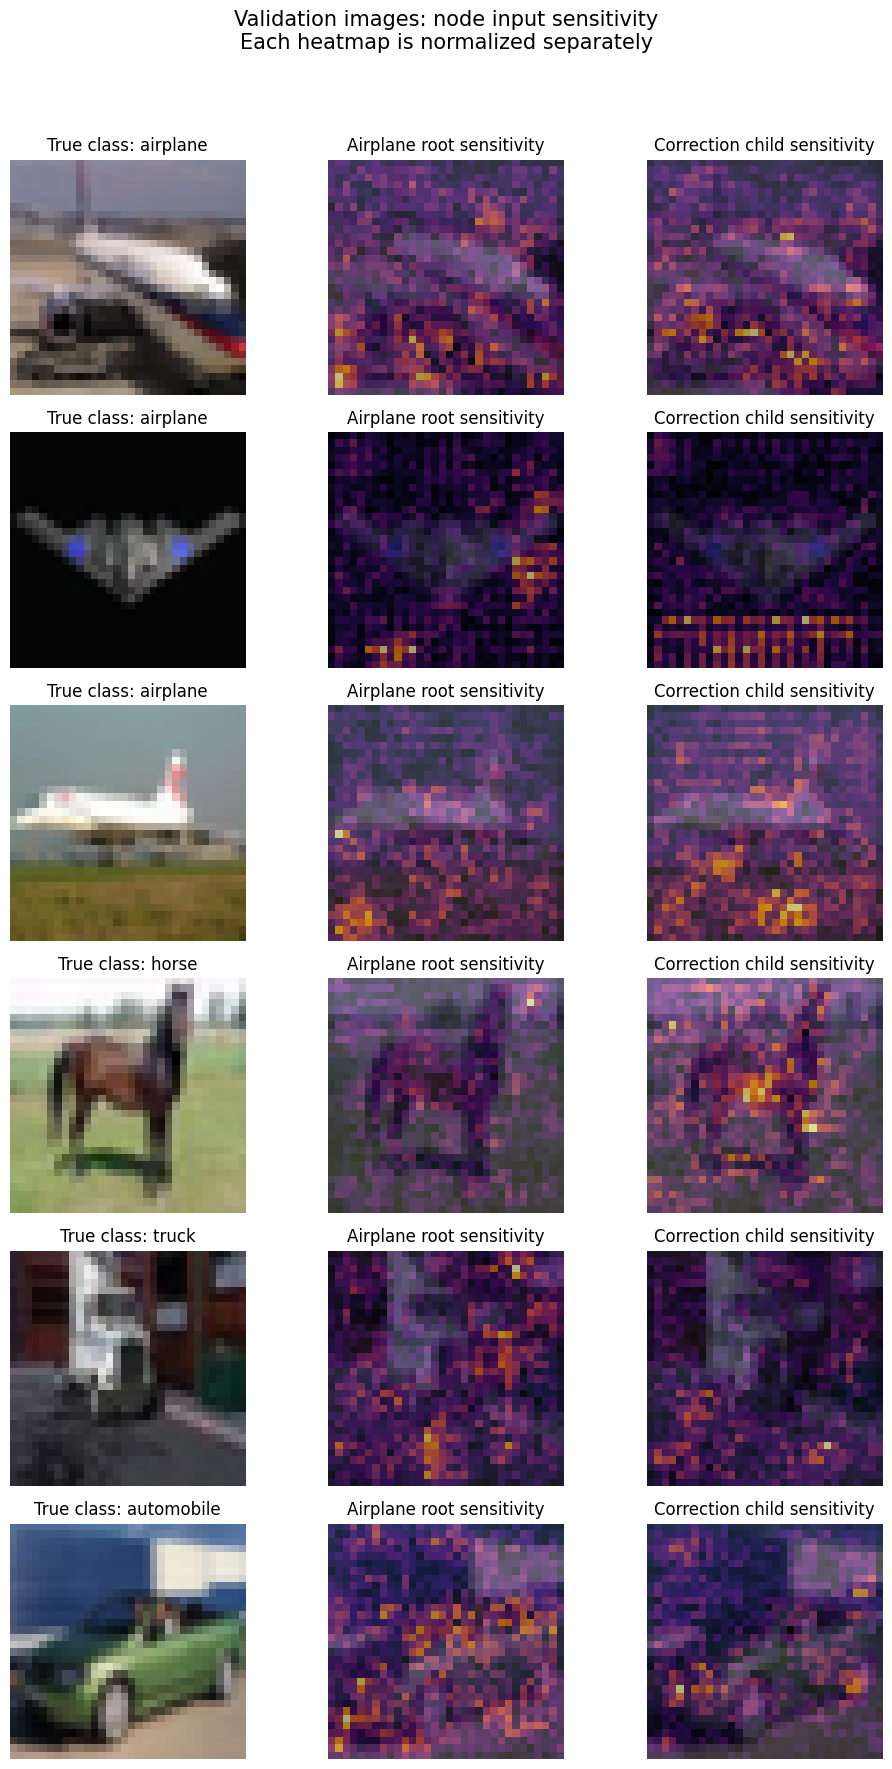

Saved: cifar10_node_sensitivity.png
Saved: cifar10_node_sensitivity.pdf


In [35]:
import matplotlib.pyplot as plt
import numpy as np

trunk.eval()
cifar_roots.eval()
airplane_B.eval()


def node_sensitivity(image, node_name):
    # Enable gradients on the input image.
    image_input = (
        image.unsqueeze(0)
        .to(device)
        .detach()
        .requires_grad_(True)
    )

    # Gradients still pass through a frozen trunk to the image.
    features = trunk(image_input)

    if node_name == "airplane_root":
        score = cifar_roots(features)[0, airplane_index]

    elif node_name == "airplane_child":
        normalized = (
            features - feature_mean.to(device)
        ) / feature_std.to(device)

        # Use the child's continuous score, before its hard threshold.
        score = airplane_B(normalized).reshape(-1)[0]

    else:
        raise ValueError("Unknown node name")

    gradient = torch.autograd.grad(
        score, image_input
    )[0]

    # Combine the three colour-channel gradients.
    sensitivity = (
        gradient.abs()
        .amax(dim=1)[0]
        .detach()
        .cpu()
        .numpy()
    )

    # Normalize each map separately for display.
    sensitivity /= max(float(sensitivity.max()), 1e-12)

    return sensitivity


# Select three airplanes and three non-airplanes from validation.
# No selection is based on the appearance of the resulting maps.
example_indices = []

for wanted_airplane in [True, False]:
    count = 0

    for index in range(len(val_dataset)):
        _, label = val_dataset[index]

        if (int(label) == airplane_index) == wanted_airplane:
            example_indices.append(index)
            count += 1

        if count == 3:
            break


fig, axes = plt.subplots(
    len(example_indices), 3,
    figsize=(10, 3 * len(example_indices)),
    squeeze=False
)

for row, index in enumerate(example_indices):
    image, label = val_dataset[index]

    # Our dataset uses ToTensor(), so pixels are in [0, 1].
    displayed_image = image.permute(1, 2, 0).cpu().numpy()
    displayed_image = np.clip(displayed_image, 0, 1)

    root_map = node_sensitivity(image, "airplane_root")
    child_map = node_sensitivity(image, "airplane_child")

    axes[row, 0].imshow(displayed_image)
    axes[row, 0].set_title(
        f"True class: {full_train_dataset.classes[int(label)]}"
    )

    axes[row, 1].imshow(displayed_image)
    axes[row, 1].imshow(
        root_map, cmap="inferno",
        alpha=0.65, vmin=0, vmax=1
    )
    axes[row, 1].set_title("Airplane root sensitivity")

    axes[row, 2].imshow(displayed_image)
    axes[row, 2].imshow(
        child_map, cmap="inferno",
        alpha=0.65, vmin=0, vmax=1
    )
    axes[row, 2].set_title("Correction child sensitivity")

    for axis in axes[row]:
        axis.axis("off")

fig.suptitle(
    "Validation images: node input sensitivity\n"
    "Each heatmap is normalized separately",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "cifar10_node_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "cifar10_node_sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved: cifar10_node_sensitivity.png")
print("Saved: cifar10_node_sensitivity.pdf")

### Interpretation of Node Sensitivity Maps

Input-gradient maps reveal different spatial sensitivity patterns
for the airplane root and its correction child, despite their use
of the same CNN features. Responses occur on both objects and
background regions. For example, the correction child shows a
strong horizontal response below the second airplane, whereas
the root responds more strongly near the right image boundary.

The maps do not demonstrate consistent localization of airplane
parts. They visualize local sensitivity of each node's continuous
score, rather than the direction of its decision or the final
classifier's prediction. Each map is normalized independently,
so brightness cannot be compared quantitatively across nodes.

The correction achieves perfect training fit without improving
validation accuracy. The visualizations provide qualitative
evidence of different node sensitivities, but do not establish
the cause of this generalization gap.

## Input Sensitivity of All Ten CIFAR-10 Root Nodes

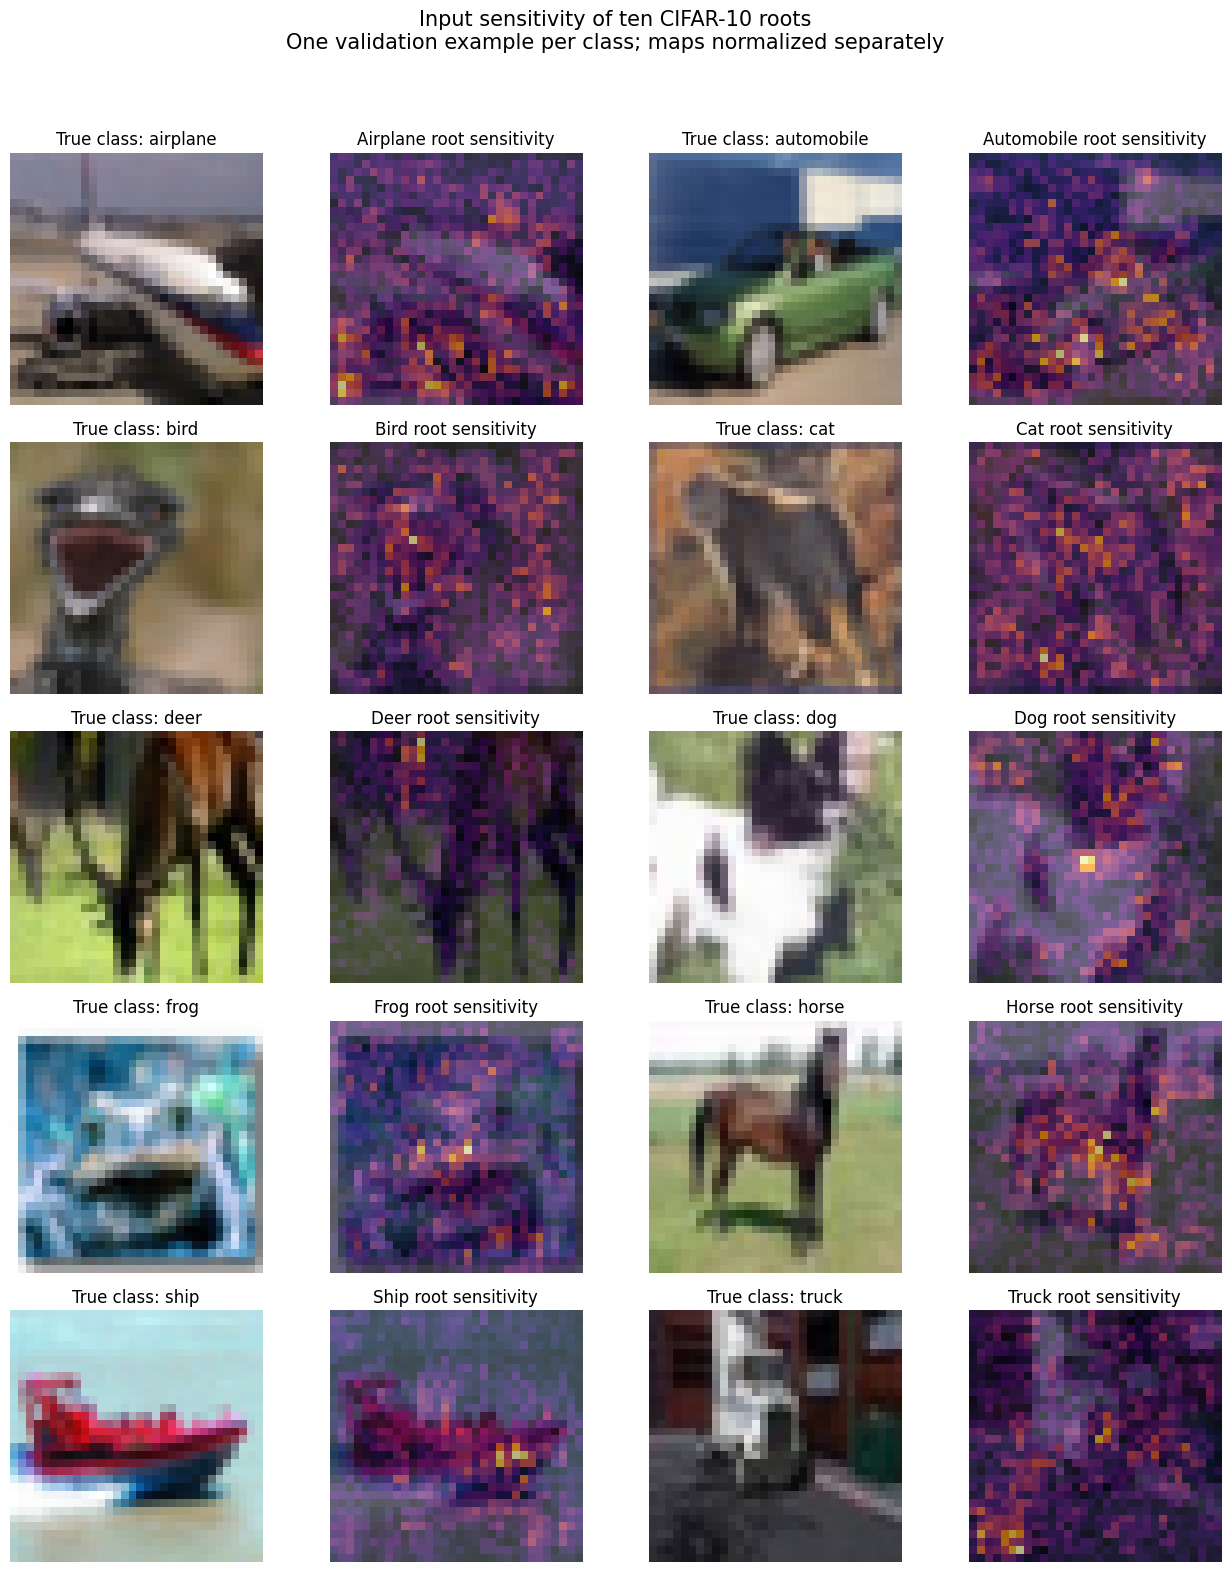

Saved: cifar10_all_root_sensitivity.png
Saved: cifar10_all_root_sensitivity.pdf


In [36]:
# Uses our existing trained trunk and cifar_roots.
trunk.eval()
cifar_roots.eval()


def class_root_sensitivity(image, class_index):
    image_input = (
        image.unsqueeze(0)
        .to(device)
        .detach()
        .requires_grad_(True)
    )

    features = trunk(image_input)
    score = cifar_roots(features)[0, class_index]

    gradient = torch.autograd.grad(
        score, image_input
    )[0]

    heatmap = (
        gradient.abs()
        .amax(dim=1)[0]
        .detach()
        .cpu()
        .numpy()
    )

    heatmap /= max(float(heatmap.max()), 1e-12)
    return heatmap


# Select the first validation example of every class.
class_examples = {}

for index in range(len(val_dataset)):
    image, label = val_dataset[index]
    label = int(label)

    if label not in class_examples:
        class_examples[label] = image

    if len(class_examples) == 10:
        break


fig, axes = plt.subplots(5, 4, figsize=(13, 16))

for class_index in range(10):
    row = class_index // 2
    column = 2 * (class_index % 2)

    image = class_examples[class_index]
    image_rgb = image.permute(1, 2, 0).cpu().numpy()
    image_rgb = np.clip(image_rgb, 0, 1)

    heatmap = class_root_sensitivity(image, class_index)
    class_name = full_train_dataset.classes[class_index]

    axes[row, column].imshow(image_rgb)
    axes[row, column].set_title(f"True class: {class_name}")

    axes[row, column + 1].imshow(image_rgb)
    axes[row, column + 1].imshow(
        heatmap,
        cmap="inferno",
        alpha=0.65,
        vmin=0,
        vmax=1
    )
    axes[row, column + 1].set_title(
        f"{class_name.capitalize()} root sensitivity"
    )

for axis in axes.flat:
    axis.axis("off")

fig.suptitle(
    "Input sensitivity of ten CIFAR-10 roots\n"
    "One validation example per class; maps normalized separately",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "cifar10_all_root_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "cifar10_all_root_sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved: cifar10_all_root_sensitivity.png")
print("Saved: cifar10_all_root_sensitivity.pdf")

### Observations Across the Ten Root Nodes

The input-gradient maps show spatially distributed sensitivity.
Some strong responses overlap object regions, such as the ship's
hull and the horse's body, while others occur in the background.
The maps therefore do not show consistent object-only localization.

Although all roots share a CNN trunk, each root has independently
learned weights. Their input sensitivities can consequently differ.

These examples provide a qualitative illustration rather than a
class-wide conclusion: only one image per class is shown, and both
the image and root change between examples. Each map is normalized
separately, so brightness does not indicate comparable sensitivity
magnitudes across roots.

## Capacity Sweep: Root Width, Training Fit, and Validation Error

Keep the CNN trunk and dataset split fixed. Train ten independent
binary roots at different hidden widths using the same training
schedule. Measure exact ten-class errors and parameter counts.

This experiment studies the root stage before correction children.
Double descent will be reported only if supported by the results.

In [37]:
import time
import csv
import gc
import torch.nn.functional as F

capacity_widths = [8, 32, 64, 128, 256, 512]
capacity_epochs = 50
capacity_results = []

capacity_train_X = X_train.detach().cpu()
capacity_train_y = y_train.detach().cpu()
capacity_val_X = X_val.detach().cpu()
capacity_val_y = y_val.detach().cpu()

capacity_counts = torch.bincount(
    capacity_train_y, minlength=10
).float()

capacity_pos_weights = (
    (len(capacity_train_y) - capacity_counts)
    / capacity_counts
).to(device)


@torch.no_grad()
def capacity_errors(network, features, labels):
    network.eval()
    errors = 0

    for start in range(0, len(labels), 512):
        batch = features[start:start + 512].to(device)
        predicted = network(batch).argmax(dim=1).cpu()

        errors += (
            predicted != labels[start:start + 512]
        ).sum().item()

    return errors


for width in capacity_widths:
    # Reset the seed and data order for each run.
    torch.manual_seed(42)

    capacity_loader = DataLoader(
        TensorDataset(capacity_train_X, capacity_train_y),
        batch_size=256,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42)
    )

    capacity_model = CIFARRoots(
        feature_mean.detach().cpu(),
        feature_std.detach().cpu(),
        hidden_width=width
    ).to(device)

    capacity_optimizer = torch.optim.Adam(
        capacity_model.parameters(), lr=0.001
    )

    capacity_loss = nn.BCEWithLogitsLoss(
        pos_weight=capacity_pos_weights
    )

    first_zero_error_epoch = None
    capacity_history = []
    start_time = time.perf_counter()

    print(f"\nTRAINING ROOT WIDTH {width}", flush=True)

    for epoch in range(1, capacity_epochs + 1):
        # Same learning-rate schedule for every width.
        if epoch == 25:
            for group in capacity_optimizer.param_groups:
                group["lr"] = 0.0001

        capacity_model.train()

        for features, labels in capacity_loader:
            features = features.to(device)
            labels = labels.to(device)

            binary_targets = F.one_hot(
                labels, num_classes=10
            ).float()

            capacity_optimizer.zero_grad(set_to_none=True)

            scores = capacity_model(features)
            loss = capacity_loss(scores, binary_targets)

            loss.backward()
            capacity_optimizer.step()

        if epoch % 10 == 0:
            train_errors = capacity_errors(
                capacity_model,
                capacity_train_X,
                capacity_train_y
            )

            val_errors = capacity_errors(
                capacity_model,
                capacity_val_X,
                capacity_val_y
            )

            if train_errors == 0 and first_zero_error_epoch is None:
                first_zero_error_epoch = epoch

            capacity_history.append({
                "epoch": epoch,
                "train_errors": train_errors,
                "val_errors": val_errors
            })

            print(
                f"Epoch {epoch}: "
                f"train errors={train_errors} | "
                f"validation errors={val_errors}",
                flush=True
            )

    root_parameters = sum(
        p.numel() for p in capacity_model.parameters()
    )

    total_parameters = root_parameters + sum(
        p.numel() for p in trunk.parameters()
    )

    result = {
        "width": width,
        "root_parameters": root_parameters,
        "total_parameters_with_trunk": total_parameters,
        "train_errors": train_errors,
        "val_errors": val_errors,
        "train_error_percent": (
            100 * train_errors / len(capacity_train_y)
        ),
        "val_error_percent": (
            100 * val_errors / len(capacity_val_y)
        ),
        "first_zero_error_checkpoint": first_zero_error_epoch,
        "seconds": round(time.perf_counter() - start_time, 1)
    }

    capacity_results.append(result)

    # Save each model for possible follow-up correction experiments.
    torch.save({
        "state": {
            name: tensor.detach().cpu()
            for name, tensor in capacity_model.state_dict().items()
        },
        "hidden_width": width,
        "history": capacity_history,
        "result": result
    }, f"cifar10_capacity_width_{width}.pt")

    # Save completed results after every width.
    with open(
        "cifar10_capacity_results.csv",
        "w",
        newline=""
    ) as file:
        writer = csv.DictWriter(
            file, fieldnames=list(result.keys())
        )
        writer.writeheader()
        writer.writerows(capacity_results)

    print(
        f"Width {width} finished | "
        f"train={100 - result['train_error_percent']:.4f}% | "
        f"validation={100 - result['val_error_percent']:.2f}% | "
        f"parameters={total_parameters:,} | "
        f"time={result['seconds']}s",
        flush=True
    )

    del capacity_model, capacity_optimizer
    gc.collect()

    if device.type == "mps":
        torch.mps.empty_cache()

print("\nSweep complete. Saved: cifar10_capacity_results.csv")


TRAINING ROOT WIDTH 8
Epoch 10: train errors=7552 | validation errors=1693
Epoch 20: train errors=4059 | validation errors=1724
Epoch 30: train errors=2414 | validation errors=1720
Epoch 40: train errors=2122 | validation errors=1741
Epoch 50: train errors=1856 | validation errors=1758
Width 8 finished | train=95.8756% | validation=64.84% | parameters=169,098 | time=45.8s

TRAINING ROOT WIDTH 32
Epoch 10: train errors=2455 | validation errors=1554
Epoch 20: train errors=274 | validation errors=1588
Epoch 30: train errors=43 | validation errors=1545
Epoch 40: train errors=24 | validation errors=1541
Epoch 50: train errors=10 | validation errors=1539
Width 32 finished | train=99.9778% | validation=69.22% | parameters=661,098 | time=51.1s

TRAINING ROOT WIDTH 64
Epoch 10: train errors=1200 | validation errors=1485
Epoch 20: train errors=69 | validation errors=1470
Epoch 30: train errors=7 | validation errors=1481
Epoch 40: train errors=4 | validation errors=1488
Epoch 50: train errors=2 

## Capacity Sweep Results: Accuracy and Model Size

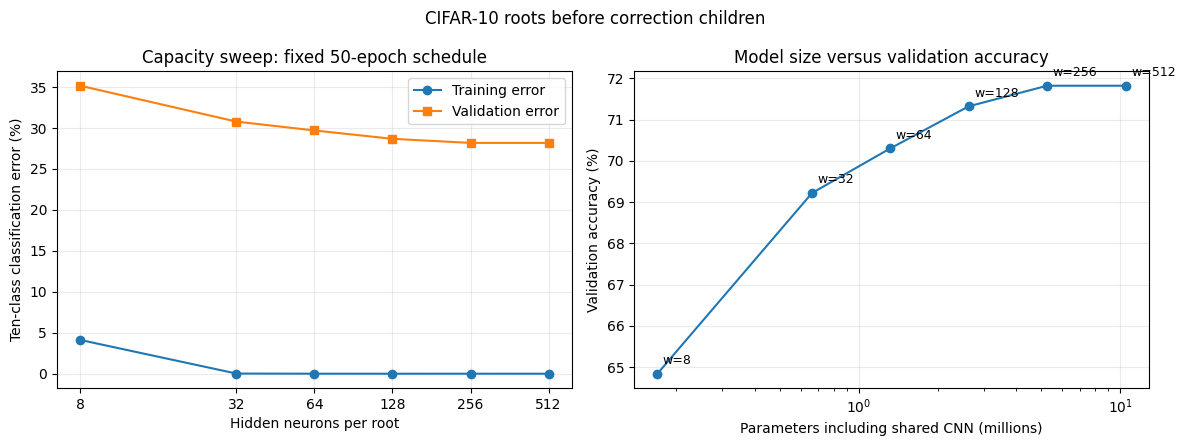

In [38]:
import csv
import matplotlib.pyplot as plt

# Read the saved results so this also works after a notebook restart.
with open("cifar10_capacity_results.csv", newline="") as file:
    sweep_rows = list(csv.DictReader(file))

sweep_rows.sort(key=lambda row: int(row["width"]))

widths = [int(row["width"]) for row in sweep_rows]
parameters = [
    int(row["total_parameters_with_trunk"])
    for row in sweep_rows
]
train_error = [
    float(row["train_error_percent"])
    for row in sweep_rows
]
val_error = [
    float(row["val_error_percent"])
    for row in sweep_rows
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel 1: capacity versus error.
axes[0].plot(widths, train_error, "o-", label="Training error")
axes[0].plot(widths, val_error, "s-", label="Validation error")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(widths)
axes[0].set_xticklabels(widths)
axes[0].set_xlabel("Hidden neurons per root")
axes[0].set_ylabel("Ten-class classification error (%)")
axes[0].set_title("Capacity sweep: fixed 50-epoch schedule")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Panel 2: size versus validation performance.
axes[1].plot(
    [count / 1e6 for count in parameters],
    [100 - error for error in val_error],
    "o-"
)

for count, error, width in zip(parameters, val_error, widths):
    axes[1].annotate(
        f"w={width}",
        (count / 1e6, 100 - error),
        xytext=(4, 7),
        textcoords="offset points",
        fontsize=9
    )

axes[1].set_xscale("log")
axes[1].set_xlabel("Parameters including shared CNN (millions)")
axes[1].set_ylabel("Validation accuracy (%)")
axes[1].set_title("Model size versus validation accuracy")
axes[1].grid(alpha=0.25)

fig.suptitle("CIFAR-10 roots before correction children")
plt.tight_layout()

plt.savefig(
    "cifar10_capacity_sweep.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "cifar10_capacity_sweep.pdf",
    bbox_inches="tight"
)
plt.show()

### Capacity and Size Findings

Increasing root width reduced final validation error from 35.16%
at width 8 to 28.18% at widths 256 and 512. This sweep did not
show a validation-error peak followed by a second descent.

No root-only run achieved exactly zero training errors within
50 epochs. Consequently, the experiment does not clearly establish
behavior beyond the exact interpolation threshold.

Width 32 was the smallest tested root-stage model achieving
greater than 99.9% training accuracy. It used 661,098 parameters,
approximately 87.4% fewer than width 256, with lower validation
accuracy (69.22% versus 71.82%).

These are exploratory results from one run per width with a fixed
training budget. They do not establish the minimum possible model
size or rule out double descent under other training conditions.

## Cats vs Dogs: Downloading the Separate Dataset

In [43]:
%pip install --upgrade certifi


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [44]:
import ssl
import certifi
import urllib.request

catsdogs_ssl_context = ssl.create_default_context(
    cafile=certifi.where()
)

catsdogs_download_opener = urllib.request.build_opener(
    urllib.request.HTTPSHandler(context=catsdogs_ssl_context)
)

urllib.request.install_opener(catsdogs_download_opener)

print("Certificate bundle configured.")

Certificate bundle configured.


## Cats vs Dogs: Downloading the Separate Dataset

In [45]:
from pathlib import Path
import urllib.request
import zipfile

# Separate variables and folders from our CIFAR experiment.
catsdogs_folder = Path("data/cats_vs_dogs")
catsdogs_folder.mkdir(parents=True, exist_ok=True)

catsdogs_zip = catsdogs_folder / "kagglecatsanddogs_5340.zip"
catsdogs_images = catsdogs_folder / "PetImages"

catsdogs_url = (
    "https://download.microsoft.com/download/"
    "3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/"
    "kagglecatsanddogs_5340.zip"
)

if not catsdogs_images.exists():
    if not catsdogs_zip.exists():
        print("Downloading Cats vs Dogs. This may take a few minutes.",
              flush=True)

        # Download to a temporary file so an interrupted download
        # is not mistaken for a completed archive.
        temporary_zip = catsdogs_zip.with_suffix(".zip.part")
        urllib.request.urlretrieve(catsdogs_url, temporary_zip)
        temporary_zip.replace(catsdogs_zip)

        print("Download complete.", flush=True)

    print("Extracting images...", flush=True)

    with zipfile.ZipFile(catsdogs_zip, "r") as archive:
        archive.extractall(catsdogs_folder)

for class_name in ["Cat", "Dog"]:
    class_folder = catsdogs_images / class_name

    if not class_folder.is_dir():
        raise FileNotFoundError(f"Missing folder: {class_folder}")

    count = len(list(class_folder.glob("*.jpg")))
    print(f"{class_name}: {count} JPEG files")

print("Dataset location:", catsdogs_images.resolve())

Download complete.
Extracting images...
Cat: 12500 JPEG files
Dog: 12500 JPEG files
Dataset location: /Users/aroma/data/cats_vs_dogs/PetImages


## Cats vs Dogs: Image Validation and Reproducible Dataset Splits

In [46]:
from pathlib import Path
from PIL import Image
import numpy as np
import csv

catsdogs_images = Path(
    "/Users/aroma/data/cats_vs_dogs/PetImages"
)

# Cat = 0, Dog = 1.
catsdogs_class_names = ["Cat", "Dog"]
catsdogs_valid_files = {0: [], 1: []}
catsdogs_invalid_files = []

for label, class_name in enumerate(catsdogs_class_names):
    image_paths = sorted(
        (catsdogs_images / class_name).glob("*.jpg")
    )

    print(f"Checking {class_name} images...", flush=True)

    for path in image_paths:
        try:
            # Fully decode the image, matching our RGB loading step.
            with Image.open(path) as image:
                image.convert("RGB").load()

            catsdogs_valid_files[label].append(path)

        except Exception as error:
            # Record invalid files without deleting the originals.
            catsdogs_invalid_files.append(
                (str(path), str(error))
            )

    print(
        f"{class_name}: "
        f"{len(catsdogs_valid_files[label])} valid images",
        flush=True
    )


# Split each class independently with a fixed seed.
catsdogs_rng = np.random.default_rng(42)

catsdogs_splits = {
    "train": [],
    "validation": [],
    "test": []
}

for label, paths in catsdogs_valid_files.items():
    order = catsdogs_rng.permutation(len(paths))

    train_end = int(0.80 * len(paths))
    validation_end = train_end + int(0.10 * len(paths))

    class_split_indices = {
        "train": order[:train_end],
        "validation": order[train_end:validation_end],
        "test": order[validation_end:]
    }

    for split_name, indices in class_split_indices.items():
        catsdogs_splits[split_name].extend(
            (paths[int(index)], label)
            for index in indices
        )


# Confirm that no file appears in more than one split.
split_path_sets = {
    name: {str(path) for path, label in samples}
    for name, samples in catsdogs_splits.items()
}

assert split_path_sets["train"].isdisjoint(
    split_path_sets["validation"]
)
assert split_path_sets["train"].isdisjoint(
    split_path_sets["test"]
)
assert split_path_sets["validation"].isdisjoint(
    split_path_sets["test"]
)


# Save relative file paths so the split can be reused elsewhere.
catsdogs_manifest = catsdogs_images.parent / "split_manifest.csv"

with catsdogs_manifest.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["relative_path", "label", "class", "split"])

    for split_name, samples in catsdogs_splits.items():
        for path, label in samples:
            writer.writerow([
                str(path.relative_to(catsdogs_images)),
                label,
                catsdogs_class_names[label],
                split_name
            ])


catsdogs_invalid_log = (
    catsdogs_images.parent / "invalid_images.csv"
)

with catsdogs_invalid_log.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["path", "error"])
    writer.writerows(catsdogs_invalid_files)


print("\nExcluded unreadable images:", len(catsdogs_invalid_files))

for split_name, samples in catsdogs_splits.items():
    cats = sum(label == 0 for path, label in samples)
    dogs = sum(label == 1 for path, label in samples)

    print(
        f"{split_name.upper()}: {len(samples)} images "
        f"| cats={cats} | dogs={dogs}"
    )

print("\nSaved split manifest:", catsdogs_manifest)
print("Saved invalid-image log:", catsdogs_invalid_log)

Checking Cat images...
Cat: 12499 valid images
Checking Dog images...


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/PIL/TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Dog: 12499 valid images

Excluded unreadable images: 2
TRAIN: 19998 images | cats=9999 | dogs=9999
VALIDATION: 2498 images | cats=1249 | dogs=1249
TEST: 2502 images | cats=1251 | dogs=1251

Saved split manifest: /Users/aroma/data/cats_vs_dogs/split_manifest.csv
Saved invalid-image log: /Users/aroma/data/cats_vs_dogs/invalid_images.csv


## Cats vs Dogs: Shared CNN Trunk and Binary Root

In [47]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image


class CatsDogsDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]

        with Image.open(path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        return image, label


catsdogs_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

catsdogs_train_dataset = CatsDogsDataset(
    catsdogs_splits["train"], catsdogs_transform
)
catsdogs_val_dataset = CatsDogsDataset(
    catsdogs_splits["validation"], catsdogs_transform
)
catsdogs_test_dataset = CatsDogsDataset(
    catsdogs_splits["test"], catsdogs_transform
)

catsdogs_train_loader = DataLoader(
    catsdogs_train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

catsdogs_val_loader = DataLoader(
    catsdogs_val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)


# Fresh networks: these do not modify our CIFAR model.
torch.manual_seed(42)

catsdogs_trunk = CNNTrunk().to(device)

catsdogs_root = BinaryNode(
    input_dim=2048,
    hidden_width=128
).to(device)

catsdogs_model = nn.Sequential(
    catsdogs_trunk,
    catsdogs_root
).to(device)

# Label convention: Cat=0, Dog=1.
catsdogs_criterion = nn.BCEWithLogitsLoss()

catsdogs_optimizer = torch.optim.Adam(
    catsdogs_model.parameters(),
    lr=0.001
)

catsdogs_history = []

# Check the shapes without using the test set.
sample_images, sample_labels = next(
    iter(catsdogs_train_loader)
)

with torch.no_grad():
    sample_features = catsdogs_trunk(
        sample_images.to(device)
    )
    sample_scores = catsdogs_model(
        sample_images.to(device)
    )

print("Device:", device)
print("Image batch:", sample_images.shape)
print("CNN features:", sample_features.shape)
print("Binary scores:", sample_scores.shape)
print("Labels: Cat=0, Dog=1")

print(
    "Parameters:",
    f"{sum(p.numel() for p in catsdogs_model.parameters()):,}"
)

Device: mps
Image batch: torch.Size([128, 3, 32, 32])
CNN features: torch.Size([128, 2048])
Binary scores: torch.Size([128])
Labels: Cat=0, Dog=1
Parameters: 267,489


In [48]:
import time

# A non-shuffled loader for measuring training accuracy.
catsdogs_train_eval_loader = DataLoader(
    catsdogs_train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)


@torch.no_grad()
def evaluate_catsdogs(network, loader):
    network.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        targets = labels.to(device).float()

        scores = network(images)
        loss = catsdogs_criterion(scores, targets)

        predicted = scores >= 0
        correct += (
            predicted == targets.bool()
        ).sum().item()

        total_loss += loss.item() * len(labels)
        total += len(labels)

    return total_loss / total, 100 * correct / total


for _ in range(20):
    epoch = len(catsdogs_history) + 1
    start = time.perf_counter()

    catsdogs_model.train()

    for images, labels in catsdogs_train_loader:
        images = images.to(device)
        targets = labels.to(device).float()

        catsdogs_optimizer.zero_grad(set_to_none=True)

        scores = catsdogs_model(images)
        loss = catsdogs_criterion(scores, targets)

        loss.backward()
        catsdogs_optimizer.step()

    train_loss, train_accuracy = evaluate_catsdogs(
        catsdogs_model, catsdogs_train_eval_loader
    )

    val_loss, val_accuracy = evaluate_catsdogs(
        catsdogs_model, catsdogs_val_loader
    )

    catsdogs_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    # Save after every epoch.
    torch.save({
        "trunk_state": catsdogs_trunk.state_dict(),
        "root_state": catsdogs_root.state_dict(),
        "optimizer_state": catsdogs_optimizer.state_dict(),
        "root_hidden_width": 128,
        "image_size": 32,
        "class_names": ["Cat", "Dog"],
        "history": catsdogs_history
    }, "catsdogs_root_checkpoint.pt")

    print(
        f"Epoch {epoch}: "
        f"train loss={train_loss:.3f}, "
        f"accuracy={train_accuracy:.2f}% | "
        f"val loss={val_loss:.3f}, "
        f"accuracy={val_accuracy:.2f}% | "
        f"time={time.perf_counter() - start:.1f}s",
        flush=True
    )

Epoch 1: train loss=0.596, accuracy=68.35% | val loss=0.606, accuracy=68.21% | time=30.9s
Epoch 2: train loss=0.549, accuracy=72.50% | val loss=0.563, accuracy=71.22% | time=31.3s
Epoch 3: train loss=0.570, accuracy=69.71% | val loss=0.585, accuracy=68.98% | time=30.6s
Epoch 4: train loss=0.509, accuracy=74.96% | val loss=0.533, accuracy=73.34% | time=32.4s
Epoch 5: train loss=0.462, accuracy=78.53% | val loss=0.494, accuracy=76.54% | time=31.1s
Epoch 6: train loss=0.465, accuracy=78.07% | val loss=0.491, accuracy=76.70% | time=32.1s
Epoch 7: train loss=0.463, accuracy=78.02% | val loss=0.496, accuracy=76.06% | time=31.0s
Epoch 8: train loss=0.430, accuracy=80.39% | val loss=0.472, accuracy=77.94% | time=31.1s
Epoch 9: train loss=0.421, accuracy=80.81% | val loss=0.480, accuracy=77.02% | time=30.9s
Epoch 10: train loss=0.419, accuracy=80.68% | val loss=0.481, accuracy=77.10% | time=29.8s
Epoch 11: train loss=0.393, accuracy=82.27% | val loss=0.466, accuracy=78.10% | time=31.3s
Epoch 12

## Cats vs Dogs: Freezing the Trunk and Caching Features

In [49]:
from torch.utils.data import TensorDataset

# Freeze only the Cats vs Dogs trunk.
catsdogs_trunk.eval()

for parameter in catsdogs_trunk.parameters():
    parameter.requires_grad_(False)


@torch.no_grad()
def extract_catsdogs_features(loader):
    feature_batches = []
    label_batches = []

    for images, labels in loader:
        features = catsdogs_trunk(images.to(device))

        feature_batches.append(features.cpu())
        label_batches.append(labels.cpu())

    return (
        torch.cat(feature_batches),
        torch.cat(label_batches)
    )


# Use non-shuffled loaders to preserve image-to-feature alignment.
catsdogs_X_train, catsdogs_y_train = extract_catsdogs_features(
    catsdogs_train_eval_loader
)

catsdogs_X_val, catsdogs_y_val = extract_catsdogs_features(
    catsdogs_val_loader
)

# Calculate normalization using training features only.
catsdogs_feature_mean = catsdogs_X_train.mean(dim=0)
catsdogs_feature_std = (
    catsdogs_X_train.std(dim=0).clamp_min(1e-6)
)

catsdogs_Z_train = (
    catsdogs_X_train - catsdogs_feature_mean
) / catsdogs_feature_std

catsdogs_Z_val = (
    catsdogs_X_val - catsdogs_feature_mean
) / catsdogs_feature_std

torch.save({
    "train_features": catsdogs_X_train,
    "train_labels": catsdogs_y_train,
    "validation_features": catsdogs_X_val,
    "validation_labels": catsdogs_y_val,
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std
}, "catsdogs_cached_features.pt")

print("Training features:", catsdogs_X_train.shape)
print("Training labels:", catsdogs_y_train.shape)
print("Validation features:", catsdogs_X_val.shape)
print("CNN trunk frozen.")
print("Saved: catsdogs_cached_features.pt")

Training features: torch.Size([19998, 2048])
Training labels: torch.Size([19998])
Validation features: torch.Size([2498, 2048])
CNN trunk frozen.
Saved: catsdogs_cached_features.pt


## Cats vs Dogs: Fitting a Binary Root on Frozen CNN Features

In [50]:
import time

torch.manual_seed(42)

# A fresh root receiving standardized features.
catsdogs_feature_root = BinaryNode(
    input_dim=2048,
    hidden_width=128
).to(device)

catsdogs_feature_optimizer = torch.optim.Adam(
    catsdogs_feature_root.parameters(),
    lr=0.001
)

catsdogs_feature_loss = nn.BCEWithLogitsLoss()

catsdogs_feature_loader = DataLoader(
    TensorDataset(
        catsdogs_Z_train,
        catsdogs_y_train.float()
    ),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

catsdogs_feature_history = []


@torch.no_grad()
def evaluate_catsdogs_node(node, features, labels):
    node.eval()
    scores = torch.cat([
        node(batch.to(device)).cpu()
        for batch in features.split(512)
    ])

    predictions = scores >= 0
    actual = labels.cpu().bool()

    errors = (predictions != actual).sum().item()

    # Dog = positive class; Cat = negative class.
    missed_dogs = ((~predictions) & actual).sum().item()
    false_dogs = (predictions & (~actual)).sum().item()

    accuracy = 100 * (1 - errors / len(actual))

    return accuracy, errors, missed_dogs, false_dogs


start_time = time.perf_counter()

for epoch in range(1, 101):
    if epoch == 51:
        for group in catsdogs_feature_optimizer.param_groups:
            group["lr"] = 0.0001

    catsdogs_feature_root.train()

    for features, targets in catsdogs_feature_loader:
        features = features.to(device)
        targets = targets.to(device)

        catsdogs_feature_optimizer.zero_grad(set_to_none=True)

        scores = catsdogs_feature_root(features)
        loss = catsdogs_feature_loss(scores, targets)

        loss.backward()
        catsdogs_feature_optimizer.step()

    if epoch % 10 == 0:
        train_result = evaluate_catsdogs_node(
            catsdogs_feature_root,
            catsdogs_Z_train,
            catsdogs_y_train
        )

        val_result = evaluate_catsdogs_node(
            catsdogs_feature_root,
            catsdogs_Z_val,
            catsdogs_y_val
        )

        catsdogs_feature_history.append({
            "epoch": epoch,
            "train_accuracy": train_result[0],
            "train_errors": train_result[1],
            "val_accuracy": val_result[0],
            "val_errors": val_result[1]
        })

        torch.save({
            "state": catsdogs_feature_root.state_dict(),
            "optimizer_state": catsdogs_feature_optimizer.state_dict(),
            "hidden_width": 128,
            "feature_mean": catsdogs_feature_mean,
            "feature_std": catsdogs_feature_std,
            "history": catsdogs_feature_history
        }, "catsdogs_feature_root.pt")

        print(
            f"Epoch {epoch}: "
            f"train={train_result[0]:.4f}% | "
            f"errors={train_result[1]} | "
            f"missed dogs={train_result[2]} | "
            f"false dogs={train_result[3]} | "
            f"validation={val_result[0]:.2f}%",
            flush=True
        )

print(f"Finished in {time.perf_counter() - start_time:.1f}s")

Epoch 10: train=99.8900% | errors=22 | missed dogs=18 | false dogs=4 | validation=80.02%
Epoch 20: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.94%
Epoch 30: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.30%
Epoch 40: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.58%
Epoch 50: train=99.9900% | errors=2 | missed dogs=1 | false dogs=1 | validation=79.82%
Epoch 60: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.86%
Epoch 70: train=99.9900% | errors=2 | missed dogs=1 | false dogs=1 | validation=79.70%
Epoch 80: train=99.9900% | errors=2 | missed dogs=1 | false dogs=1 | validation=79.94%
Epoch 90: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.74%
Epoch 100: train=99.9900% | errors=2 | missed dogs=0 | false dogs=2 | validation=79.78%
Finished in 21.0s


## Cats vs Dogs: Training the Downward Correction Child

In [51]:
import copy

catsdogs_feature_root.eval()

with torch.no_grad():
    catsdogs_root_train_scores = torch.cat([
        catsdogs_feature_root(batch.to(device)).cpu()
        for batch in catsdogs_Z_train.split(512)
    ])

catsdogs_actual_dog = catsdogs_y_train.bool()
catsdogs_predicted_dog = catsdogs_root_train_scores >= 0

catsdogs_false_dogs = (
    catsdogs_predicted_dog & (~catsdogs_actual_dog)
)

# Protect genuine dogs and correct false dog predictions.
# Correctly rejected cats are ignored for this child's task.
catsdogs_B_mask = catsdogs_actual_dog | catsdogs_false_dogs

catsdogs_B_features = catsdogs_Z_train[catsdogs_B_mask]
catsdogs_B_targets = (
    catsdogs_false_dogs[catsdogs_B_mask].float()
)

positive_count = int(catsdogs_B_targets.sum().item())
negative_count = len(catsdogs_B_targets) - positive_count

print("False dog predictions to correct:", positive_count)
print("Actual dogs to protect:", negative_count)

if positive_count == 0:
    raise ValueError("No downward correction child is needed.")

torch.manual_seed(42)

catsdogs_child_B = BinaryNode(
    input_dim=2048,
    hidden_width=32
).to(device)

catsdogs_B_optimizer = torch.optim.Adam(
    catsdogs_child_B.parameters(), lr=0.001
)

catsdogs_B_loss = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [negative_count / positive_count],
        device=device
    )
)

catsdogs_B_loader = DataLoader(
    TensorDataset(catsdogs_B_features, catsdogs_B_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

# Keep the best checked child, rather than only the last epoch.
catsdogs_B_best_key = None
catsdogs_B_best_state = None
catsdogs_B_best_epoch = None

for epoch in range(1, 101):
    if epoch == 51:
        for group in catsdogs_B_optimizer.param_groups:
            group["lr"] = 0.0001

    catsdogs_child_B.train()

    for features, targets in catsdogs_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        catsdogs_B_optimizer.zero_grad(set_to_none=True)

        loss = catsdogs_B_loss(
            catsdogs_child_B(features), targets
        )

        loss.backward()
        catsdogs_B_optimizer.step()

    if epoch % 10 == 0:
        _, _, missed, unwanted = evaluate_catsdogs_node(
            catsdogs_child_B,
            catsdogs_B_features,
            catsdogs_B_targets
        )

        # Prioritize detecting both root errors, then protecting dogs.
        key = (missed, unwanted)

        if catsdogs_B_best_key is None or key < catsdogs_B_best_key:
            catsdogs_B_best_key = key
            catsdogs_B_best_epoch = epoch
            catsdogs_B_best_state = copy.deepcopy(
                catsdogs_child_B.state_dict()
            )

        print(
            f"Epoch {epoch}: "
            f"missed corrections={missed} | "
            f"dogs flagged for unwanted correction={unwanted}",
            flush=True
        )

        if missed == 0 and unwanted == 0:
            break

catsdogs_child_B.load_state_dict(catsdogs_B_best_state)
catsdogs_child_B.eval()

torch.save({
    "state": catsdogs_child_B.state_dict(),
    "hidden_width": 32,
    "best_epoch": catsdogs_B_best_epoch,
    "task_errors": {
        "missed_corrections": catsdogs_B_best_key[0],
        "unwanted_corrections": catsdogs_B_best_key[1]
    },
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std
}, "catsdogs_downward_child.pt")

print(
    f"Restored epoch {catsdogs_B_best_epoch}: "
    f"missed={catsdogs_B_best_key[0]}, "
    f"unwanted={catsdogs_B_best_key[1]}"
)

False dog predictions to correct: 2
Actual dogs to protect: 9999
Epoch 10: missed corrections=0 | dogs flagged for unwanted correction=24
Epoch 20: missed corrections=0 | dogs flagged for unwanted correction=5
Epoch 30: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 40: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 50: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 60: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 70: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 80: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 90: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 100: missed corrections=0 | dogs flagged for unwanted correction=4
Restored epoch 30: missed=0, unwanted=4


## Cats vs Dogs: Selecting the Correction Strength and Evaluating the Tree

In [52]:
@torch.no_grad()
def catsdogs_tree_components(features):
    catsdogs_feature_root.eval()
    catsdogs_child_B.eval()

    root_scores = []
    child_flags = []

    for batch in features.split(512):
        batch = batch.to(device)

        root_scores.append(
            catsdogs_feature_root(batch).cpu()
        )
        child_flags.append(
            (catsdogs_child_B(batch) >= 0).cpu()
        )

    return torch.cat(root_scores), torch.cat(child_flags)


cd_train_scores, cd_train_flags = catsdogs_tree_components(
    catsdogs_Z_train
)

cd_actual = catsdogs_y_train.cpu().bool()

# Predictions can change only when b crosses a flagged image's
# root score. Check every nonnegative breakpoint and the intervals.
cd_breakpoints = torch.unique(
    cd_train_scores[
        cd_train_flags & (cd_train_scores >= 0)
    ].double()
).sort().values

cd_candidates = [0.0]

if len(cd_breakpoints):
    first = cd_breakpoints[0].item()

    if first > 0:
        cd_candidates.append(first / 2)

    cd_candidates.extend(cd_breakpoints.tolist())

    cd_candidates.extend(
        (
            (cd_breakpoints[:-1] + cd_breakpoints[1:]) / 2
        ).tolist()
    )

    last = cd_breakpoints[-1].item()
    cd_candidates.append(last + max(1.0, abs(last) * 0.01))

cd_best_key = None
catsdogs_best_b = 0.0

for b in sorted(set(cd_candidates)):
    corrected_scores = (
        cd_train_scores.double() - b * cd_train_flags.double()
    )
    predicted = corrected_scores >= 0

    errors = (predicted != cd_actual).sum().item()

    # Prefer fewer training errors, then a smaller correction.
    key = (errors, b)

    if cd_best_key is None or key < cd_best_key:
        cd_best_key = key
        catsdogs_best_b = b

print(f"Selected correction strength b = {catsdogs_best_b:.8f}")


def report_catsdogs_tree(name, scores, flags, labels):
    actual = labels.cpu().bool()

    results = {}

    for model_name, strength in [
        ("Root", 0.0),
        ("Root + child B", catsdogs_best_b)
    ]:
        corrected_scores = (
            scores.double() - strength * flags.double()
        )
        predicted = corrected_scores >= 0

        errors = (predicted != actual).sum().item()
        missed_dogs = ((~predicted) & actual).sum().item()
        false_dogs = (predicted & (~actual)).sum().item()
        accuracy = 100 * (1 - errors / len(actual))

        results[model_name] = {
            "accuracy": accuracy,
            "errors": errors,
            "missed_dogs": missed_dogs,
            "false_dogs": false_dogs
        }

        print(
            f"{name} | {model_name}: "
            f"accuracy={accuracy:.4f}% | errors={errors} | "
            f"missed dogs={missed_dogs} | false dogs={false_dogs}"
        )

    return results


catsdogs_tree_train_results = report_catsdogs_tree(
    "TRAIN",
    cd_train_scores,
    cd_train_flags,
    catsdogs_y_train
)

cd_val_scores, cd_val_flags = catsdogs_tree_components(
    catsdogs_Z_val
)

catsdogs_tree_val_results = report_catsdogs_tree(
    "VALIDATION",
    cd_val_scores,
    cd_val_flags,
    catsdogs_y_val
)

Selected correction strength b = 0.00000000
TRAIN | Root: accuracy=99.9900% | errors=2 | missed dogs=0 | false dogs=2
TRAIN | Root + child B: accuracy=99.9900% | errors=2 | missed dogs=0 | false dogs=2
VALIDATION | Root: accuracy=79.7838% | errors=505 | missed dogs=261 | false dogs=244
VALIDATION | Root + child B: accuracy=79.7838% | errors=505 | missed dogs=261 | false dogs=244


## Diagnosing the Downward Child: Root-Score Margins

In [53]:
# Both mistaken cats and genuine dogs activate child B.
# Compare their root scores: subtraction must cross these scores
# to change a dog prediction into a cat prediction.

cd_false_dog_mask = (
    (~cd_actual) & (cd_train_scores >= 0)
)

cd_flagged_dog_mask = cd_actual & cd_train_flags

print("Root scores of the two cats predicted as dogs:")
print(cd_train_scores[cd_false_dog_mask].tolist())

print("\nRoot scores of genuine dogs flagged by child B:")
print(cd_train_scores[cd_flagged_dog_mask].tolist())

print("\nChild detects both mistaken cats:",
      bool(cd_train_flags[cd_false_dog_mask].all()))

Root scores of the two cats predicted as dogs:
[0.5933709144592285, 2.585129499435425]

Root scores of genuine dogs flagged by child B:
[0.5933709144592285, 2.585129499435425, 2.585129499435425, 2.585129499435425]

Child detects both mistaken cats: True


## Checking Opposite-Label Examples for Identical Features and Images

In [54]:
cd_bad_cat_indices = torch.where(cd_false_dog_mask)[0]
cd_dog_indices = torch.where(catsdogs_y_train == 1)[0]

for cat_index_tensor in cd_bad_cat_indices:
    cat_index = int(cat_index_tensor)
    cat_features = catsdogs_X_train[cat_index]

    # Find genuine dogs with exactly the same cached CNN features.
    matching_dogs = []

    for dog_indices in cd_dog_indices.split(512):
        dog_features = catsdogs_X_train[dog_indices]

        identical = (dog_features == cat_features).all(dim=1)

        matching_dogs.extend(
            dog_indices[identical].tolist()
        )

    cat_path = catsdogs_train_dataset.samples[cat_index][0]
    cat_image, _ = catsdogs_train_dataset[cat_index]

    print("\nCAT:", cat_path)
    print("Dogs with identical CNN features:", len(matching_dogs))

    for dog_index in matching_dogs:
        dog_path = catsdogs_train_dataset.samples[dog_index][0]
        dog_image, _ = catsdogs_train_dataset[dog_index]

        same_resized_image = torch.equal(cat_image, dog_image)

        print("  DOG:", dog_path)
        print("  Identical 32x32 image:", same_resized_image)
        print(
            "  Maximum pixel difference:",
            (cat_image - dog_image).abs().max().item()
        )


CAT: /Users/aroma/data/cats_vs_dogs/PetImages/Cat/8456.jpg
Dogs with identical CNN features: 1
  DOG: /Users/aroma/data/cats_vs_dogs/PetImages/Dog/8736.jpg
  Identical 32x32 image: True
  Maximum pixel difference: 0.0

CAT: /Users/aroma/data/cats_vs_dogs/PetImages/Cat/11565.jpg
Dogs with identical CNN features: 3
  DOG: /Users/aroma/data/cats_vs_dogs/PetImages/Dog/2877.jpg
  Identical 32x32 image: True
  Maximum pixel difference: 0.0
  DOG: /Users/aroma/data/cats_vs_dogs/PetImages/Dog/10797.jpg
  Identical 32x32 image: True
  Maximum pixel difference: 0.0
  DOG: /Users/aroma/data/cats_vs_dogs/PetImages/Dog/10401.jpg
  Identical 32x32 image: True
  Maximum pixel difference: 0.0


### Conflicting Labels Impose an Interpolation Limit

Two groups of training examples have exactly identical images
after 32 × 32 preprocessing but conflicting Cat/Dog labels.
The groups contain one cat and one dog, and one cat and three
dogs, respectively.

Any deterministic classifier operating on these inputs must
make at least two training errors. Our root makes exactly two
errors, achieving 99.99% accuracy and attaining this upper bound.

The downward child activates on both mistaken cats and their
identical dog counterparts. Consequently, its corrections cannot
separate these examples. Training-based selection chooses b=0,
leaving the root predictions unchanged.

This finding applies to the current preprocessing; it does not
establish that the original full-resolution files are identical.

## Cats vs Dogs: A Smaller Root for the Correction-Tree Experiment

In [55]:
torch.manual_seed(42)

catsdogs_small_root = BinaryNode(
    input_dim=2048,
    hidden_width=8
).to(device)

catsdogs_small_optimizer = torch.optim.Adam(
    catsdogs_small_root.parameters(), lr=0.001
)

catsdogs_small_loss = nn.BCEWithLogitsLoss()

catsdogs_small_loader = DataLoader(
    TensorDataset(
        catsdogs_Z_train,
        catsdogs_y_train.float()
    ),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

catsdogs_small_history = []

for epoch in range(1, 101):
    if epoch == 51:
        for group in catsdogs_small_optimizer.param_groups:
            group["lr"] = 0.0001

    catsdogs_small_root.train()

    for features, targets in catsdogs_small_loader:
        features = features.to(device)
        targets = targets.to(device)

        catsdogs_small_optimizer.zero_grad(set_to_none=True)

        loss = catsdogs_small_loss(
            catsdogs_small_root(features), targets
        )

        loss.backward()
        catsdogs_small_optimizer.step()

    if epoch % 10 == 0:
        train_result = evaluate_catsdogs_node(
            catsdogs_small_root,
            catsdogs_Z_train,
            catsdogs_y_train
        )

        val_result = evaluate_catsdogs_node(
            catsdogs_small_root,
            catsdogs_Z_val,
            catsdogs_y_val
        )

        catsdogs_small_history.append({
            "epoch": epoch,
            "train_accuracy": train_result[0],
            "train_errors": train_result[1],
            "val_accuracy": val_result[0],
            "val_errors": val_result[1]
        })

        print(
            f"Epoch {epoch}: "
            f"train={train_result[0]:.4f}% | "
            f"errors={train_result[1]} | "
            f"missed dogs={train_result[2]} | "
            f"false dogs={train_result[3]} | "
            f"validation={val_result[0]:.2f}%",
            flush=True
        )

torch.save({
    "state": catsdogs_small_root.state_dict(),
    "hidden_width": 8,
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std,
    "history": catsdogs_small_history
}, "catsdogs_small_root.pt")

small_root_parameters = sum(
    p.numel() for p in catsdogs_small_root.parameters()
)
trunk_parameters = sum(
    p.numel() for p in catsdogs_trunk.parameters()
)

print(
    "Small root + shared CNN parameters:",
    f"{small_root_parameters + trunk_parameters:,}"
)

Epoch 10: train=93.0093% | errors=1398 | missed dogs=583 | false dogs=815 | validation=79.98%
Epoch 20: train=97.1197% | errors=576 | missed dogs=326 | false dogs=250 | validation=79.18%
Epoch 30: train=99.0599% | errors=188 | missed dogs=105 | false dogs=83 | validation=78.86%
Epoch 40: train=99.5950% | errors=81 | missed dogs=10 | false dogs=71 | validation=78.86%
Epoch 50: train=99.7300% | errors=54 | missed dogs=1 | false dogs=53 | validation=78.50%
Epoch 60: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.38%
Epoch 70: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.62%
Epoch 80: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.54%
Epoch 90: train=99.7350% | errors=53 | missed dogs=0 | false dogs=53 | validation=78.30%
Epoch 100: train=99.7400% | errors=52 | missed dogs=0 | false dogs=52 | validation=78.58%
Small root + shared CNN parameters: 21,489


## Cats vs Dogs: An Eight-Neuron Downward Child for the Small Root

In [56]:
import copy

catsdogs_small_root.eval()

with torch.no_grad():
    cd_small_train_scores = torch.cat([
        catsdogs_small_root(batch.to(device)).cpu()
        for batch in catsdogs_Z_train.split(512)
    ])

cd_small_actual_dog = catsdogs_y_train.bool()
cd_small_predicted_dog = cd_small_train_scores >= 0

cd_small_false_dogs = (
    cd_small_predicted_dog & (~cd_small_actual_dog)
)

# Child should activate on false dogs and remain off on genuine dogs.
cd_small_B_mask = cd_small_actual_dog | cd_small_false_dogs
cd_small_B_features = catsdogs_Z_train[cd_small_B_mask]
cd_small_B_targets = (
    cd_small_false_dogs[cd_small_B_mask].float()
)

cd_small_positive_count = int(cd_small_B_targets.sum().item())
cd_small_negative_count = (
    len(cd_small_B_targets) - cd_small_positive_count
)

print("False dog predictions:", cd_small_positive_count)
print("Genuine dogs to protect:", cd_small_negative_count)

if cd_small_positive_count == 0:
    raise ValueError("No downward child is needed.")

torch.manual_seed(42)

catsdogs_small_child_B = BinaryNode(
    input_dim=2048, hidden_width=8
).to(device)

cd_small_B_optimizer = torch.optim.Adam(
    catsdogs_small_child_B.parameters(), lr=0.001
)

cd_small_B_loss = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [cd_small_negative_count / cd_small_positive_count],
        device=device
    )
)

cd_small_B_loader = DataLoader(
    TensorDataset(cd_small_B_features, cd_small_B_targets),
    batch_size=256,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42)
)

cd_small_B_best_key = None
cd_small_B_best_state = None
cd_small_B_best_epoch = None
cd_small_B_history = []

for epoch in range(1, 101):
    if epoch == 51:
        for group in cd_small_B_optimizer.param_groups:
            group["lr"] = 0.0001

    catsdogs_small_child_B.train()

    for features, targets in cd_small_B_loader:
        features = features.to(device)
        targets = targets.to(device)

        cd_small_B_optimizer.zero_grad(set_to_none=True)

        loss = cd_small_B_loss(
            catsdogs_small_child_B(features), targets
        )
        loss.backward()
        cd_small_B_optimizer.step()

    if epoch % 10 == 0:
        _, _, missed, unwanted = evaluate_catsdogs_node(
            catsdogs_small_child_B,
            cd_small_B_features,
            cd_small_B_targets
        )

        # Balance the two task error rates for checkpoint selection.
        balanced_error = 0.5 * (
            missed / cd_small_positive_count
            + unwanted / cd_small_negative_count
        )
        key = (balanced_error, missed + unwanted)

        cd_small_B_history.append({
            "epoch": epoch,
            "missed_corrections": missed,
            "unwanted_corrections": unwanted,
            "balanced_error": balanced_error
        })

        if cd_small_B_best_key is None or key < cd_small_B_best_key:
            cd_small_B_best_key = key
            cd_small_B_best_epoch = epoch
            cd_small_B_best_state = copy.deepcopy(
                catsdogs_small_child_B.state_dict()
            )

        print(
            f"Epoch {epoch}: missed corrections={missed} | "
            f"dogs flagged for unwanted correction={unwanted}",
            flush=True
        )

catsdogs_small_child_B.load_state_dict(cd_small_B_best_state)
catsdogs_small_child_B.eval()

torch.save({
    "state": catsdogs_small_child_B.state_dict(),
    "hidden_width": 8,
    "best_epoch": cd_small_B_best_epoch,
    "history": cd_small_B_history,
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std
}, "catsdogs_small_child_B.pt")

print("Restored child checkpoint:", cd_small_B_best_epoch)

cd_small_tree_parameters = (
    sum(p.numel() for p in catsdogs_trunk.parameters())
    + sum(p.numel() for p in catsdogs_small_root.parameters())
    + sum(p.numel() for p in catsdogs_small_child_B.parameters())
    + 1  # Correction strength, to be selected next.
)

print(
    "Proposed tree parameters:",
    f"{cd_small_tree_parameters:,}"
)

False dog predictions: 52
Genuine dogs to protect: 9999
Epoch 10: missed corrections=0 | dogs flagged for unwanted correction=124
Epoch 20: missed corrections=0 | dogs flagged for unwanted correction=13
Epoch 30: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 40: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 50: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 60: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 70: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 80: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 90: missed corrections=0 | dogs flagged for unwanted correction=4
Epoch 100: missed corrections=0 | dogs flagged for unwanted correction=4
Restored child checkpoint: 30
Proposed tree parameters: 37,891


## Cats vs Dogs: Evaluating the Compact Correction Tree

In [57]:
@torch.no_grad()
def cd_compact_components(features):
    catsdogs_small_root.eval()
    catsdogs_small_child_B.eval()

    scores, flags = [], []

    for batch in features.split(512):
        batch = batch.to(device)
        scores.append(catsdogs_small_root(batch).cpu())
        flags.append((catsdogs_small_child_B(batch) >= 0).cpu())

    return torch.cat(scores), torch.cat(flags)


cd_compact_train_scores, cd_compact_train_flags = (
    cd_compact_components(catsdogs_Z_train)
)

cd_compact_actual = catsdogs_y_train.cpu().bool()

# Check all training-score breakpoints and intervals.
breakpoints = torch.unique(
    cd_compact_train_scores[
        cd_compact_train_flags & (cd_compact_train_scores >= 0)
    ].double()
).sort().values

candidates = [0.0]

if len(breakpoints):
    first = breakpoints[0].item()

    if first > 0:
        candidates.append(first / 2)

    candidates.extend(breakpoints.tolist())
    candidates.extend(
        ((breakpoints[:-1] + breakpoints[1:]) / 2).tolist()
    )

    last = breakpoints[-1].item()
    candidates.append(last + max(1.0, abs(last) * 0.01))

best_key = None
catsdogs_compact_b = 0.0

for strength in sorted(set(candidates)):
    corrected = (
        cd_compact_train_scores.double()
        - strength * cd_compact_train_flags.double()
    )

    errors = (
        (corrected >= 0) != cd_compact_actual
    ).sum().item()

    key = (errors, strength)

    if best_key is None or key < best_key:
        best_key = key
        catsdogs_compact_b = strength

print(f"Selected strength b = {catsdogs_compact_b:.8f}")


def cd_report_compact(name, scores, flags, labels):
    actual = labels.cpu().bool()
    results = {}

    for model_name, strength in [
        ("Small root", 0.0),
        ("Compact tree", catsdogs_compact_b)
    ]:
        corrected = (
            scores.double() - strength * flags.double()
        )
        predicted = corrected >= 0

        errors = (predicted != actual).sum().item()
        missed = ((~predicted) & actual).sum().item()
        false = (predicted & (~actual)).sum().item()
        accuracy = 100 * (1 - errors / len(actual))

        results[model_name] = {
            "accuracy": accuracy,
            "errors": errors,
            "missed_dogs": missed,
            "false_dogs": false
        }

        print(
            f"{name} | {model_name}: "
            f"accuracy={accuracy:.4f}% | errors={errors} | "
            f"missed dogs={missed} | false dogs={false}"
        )

    return results


catsdogs_compact_train_results = cd_report_compact(
    "TRAIN",
    cd_compact_train_scores,
    cd_compact_train_flags,
    catsdogs_y_train
)

cd_compact_val_scores, cd_compact_val_flags = (
    cd_compact_components(catsdogs_Z_val)
)

catsdogs_compact_val_results = cd_report_compact(
    "VALIDATION",
    cd_compact_val_scores,
    cd_compact_val_flags,
    catsdogs_y_val
)

# Save the complete compact tree and measured results.
torch.save({
    "trunk_state": catsdogs_trunk.state_dict(),
    "root_state": catsdogs_small_root.state_dict(),
    "child_B_state": catsdogs_small_child_B.state_dict(),
    "root_hidden_width": 8,
    "child_hidden_width": 8,
    "feature_mean": catsdogs_feature_mean,
    "feature_std": catsdogs_feature_std,
    "correction_strength": catsdogs_compact_b,
    "child_threshold": 0.0,
    "image_size": 32,
    "class_names": ["Cat", "Dog"],
    "parameter_count": cd_small_tree_parameters,
    "train_results": catsdogs_compact_train_results,
    "validation_results": catsdogs_compact_val_results,
    "score_arithmetic": "float64 after node inference"
}, "catsdogs_compact_tree.pt")

print("Saved: catsdogs_compact_tree.pt")

Selected strength b = 1.97952795
TRAIN | Small root: accuracy=99.7400% | errors=52 | missed dogs=0 | false dogs=52
TRAIN | Compact tree: accuracy=99.9800% | errors=4 | missed dogs=4 | false dogs=0
VALIDATION | Small root: accuracy=78.5829% | errors=535 | missed dogs=285 | false dogs=250
VALIDATION | Compact tree: accuracy=78.6229% | errors=534 | missed dogs=285 | false dogs=249
Saved: catsdogs_compact_tree.pt


### Compact Correction-Tree Results

An eight-neuron root and eight-neuron downward child, sharing
a frozen CNN trunk, use 37,891 parameters including the correction
strength. Training-only selection gives b = 1.97952795.

The child reduces training errors from 52 to 4, improving accuracy
from 99.74% to 99.98%. It removes all false dog predictions but
introduces four missed dogs. Conflicting labels on identical
preprocessed images prevent perfect classification; this tree
remains two errors above the established minimum of two.

Validation errors decrease from 535 to 534. This one-image
improvement provides limited evidence of a generalization benefit.

Compared with the 128-neuron root, the compact tree uses 85.8%
fewer parameters, with slightly lower training and validation
accuracy. It demonstrates useful correction with small neural
nodes, rather than establishing the smallest possible network.

## Cats vs Dogs: Root and Correction-Child Sensitivity Maps

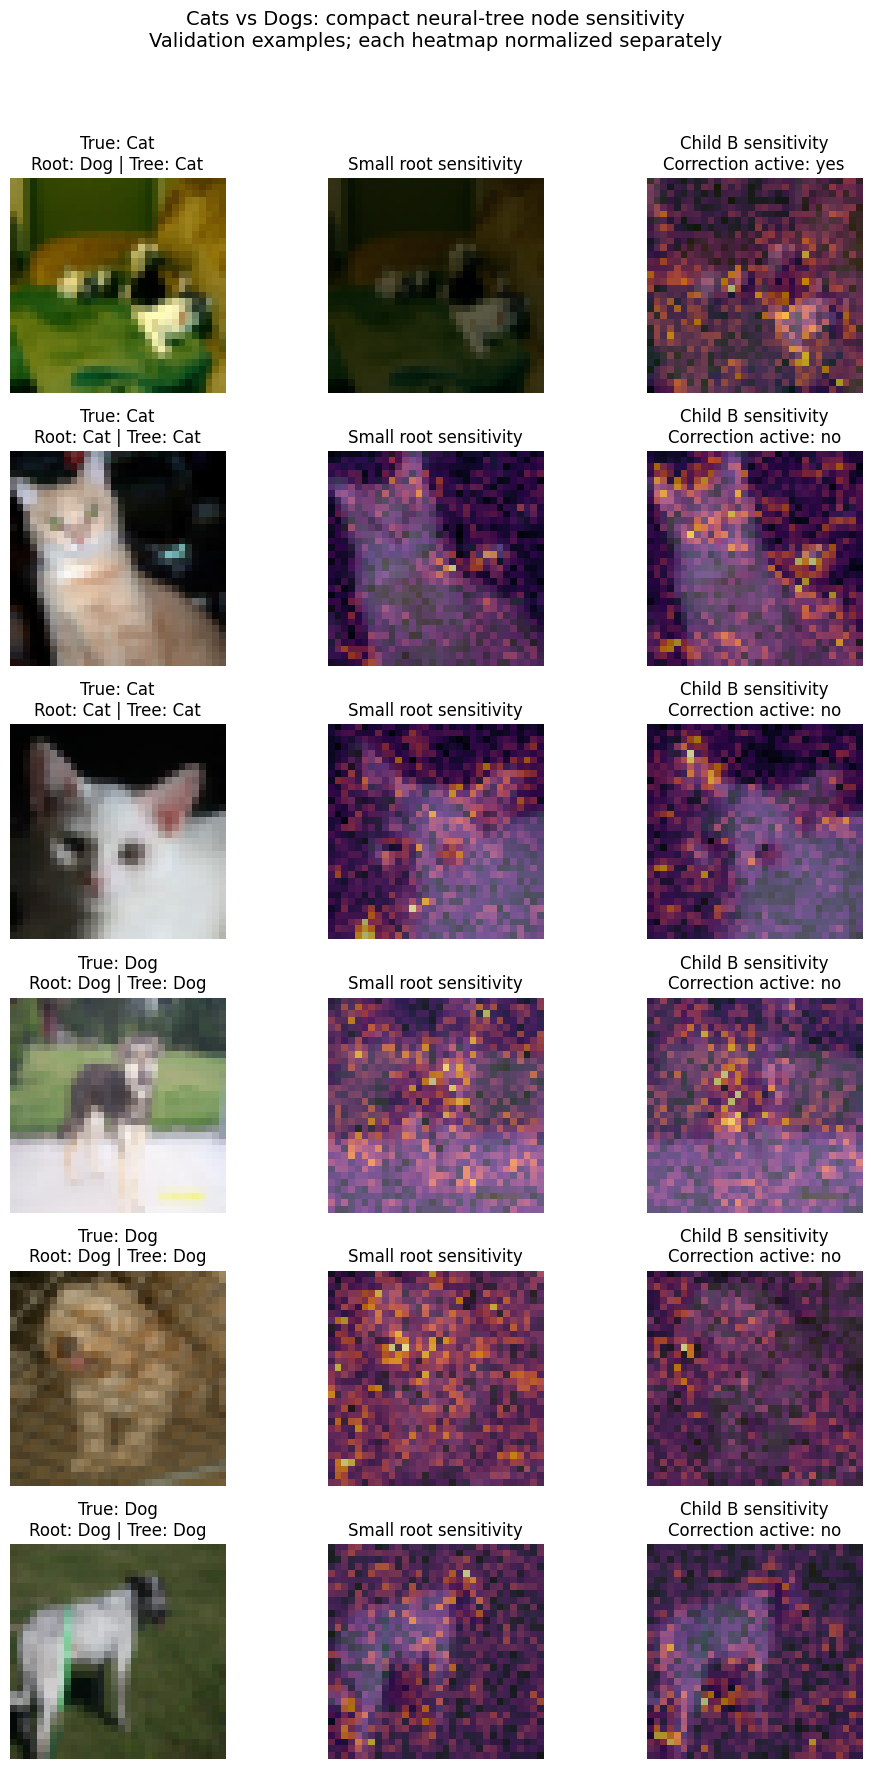

In [58]:
import numpy as np
import matplotlib.pyplot as plt

catsdogs_trunk.eval()
catsdogs_small_root.eval()
catsdogs_small_child_B.eval()


def cd_node_sensitivity(image, node_name):
    image_input = (
        image.unsqueeze(0)
        .to(device)
        .detach()
        .requires_grad_(True)
    )

    features = catsdogs_trunk(image_input)

    normalized = (
        features - catsdogs_feature_mean.to(device)
    ) / catsdogs_feature_std.to(device)

    if node_name == "root":
        score = catsdogs_small_root(normalized).reshape(-1)[0]

    elif node_name == "child":
        # Differentiate the continuous score BEFORE thresholding.
        score = catsdogs_small_child_B(normalized).reshape(-1)[0]

    else:
        raise ValueError("Choose 'root' or 'child'.")

    gradient = torch.autograd.grad(score, image_input)[0]

    heatmap = (
        gradient.abs()
        .amax(dim=1)[0]
        .detach()
        .cpu()
        .numpy()
    )

    heatmap /= max(float(heatmap.max()), 1e-12)
    return heatmap


# First three validation examples from each class.
cd_visual_indices = []

for wanted_label in [0, 1]:
    selected = 0

    for index, (_, label) in enumerate(
        catsdogs_val_dataset.samples
    ):
        if label == wanted_label:
            cd_visual_indices.append(index)
            selected += 1

        if selected == 3:
            break


fig, axes = plt.subplots(
    len(cd_visual_indices), 3,
    figsize=(10, 18),
    squeeze=False
)

for row, index in enumerate(cd_visual_indices):
    image, label = catsdogs_val_dataset[index]
    image_rgb = image.permute(1, 2, 0).cpu().numpy()
    image_rgb = np.clip(image_rgb, 0, 1)

    root_map = cd_node_sensitivity(image, "root")
    child_map = cd_node_sensitivity(image, "child")

    # Display the actual root and tree decisions.
    with torch.no_grad():
        features = catsdogs_trunk(
            image.unsqueeze(0).to(device)
        )
        normalized = (
            features - catsdogs_feature_mean.to(device)
        ) / catsdogs_feature_std.to(device)

        root_score = catsdogs_small_root(normalized).item()
        child_active = int(
            catsdogs_small_child_B(normalized).item() >= 0
        )

        tree_score = (
            root_score - catsdogs_compact_b * child_active
        )

    root_label = "Dog" if root_score >= 0 else "Cat"
    tree_label = "Dog" if tree_score >= 0 else "Cat"

    axes[row, 0].imshow(image_rgb)
    axes[row, 0].set_title(
        f"True: {catsdogs_class_names[label]}\n"
        f"Root: {root_label} | Tree: {tree_label}"
    )

    axes[row, 1].imshow(image_rgb)
    axes[row, 1].imshow(
        root_map, cmap="inferno",
        alpha=0.65, vmin=0, vmax=1
    )
    axes[row, 1].set_title("Small root sensitivity")

    axes[row, 2].imshow(image_rgb)
    axes[row, 2].imshow(
        child_map, cmap="inferno",
        alpha=0.65, vmin=0, vmax=1
    )
    axes[row, 2].set_title(
        f"Child B sensitivity\n"
        f"Correction active: {'yes' if child_active else 'no'}"
    )

for axis in axes.flat:
    axis.axis("off")

fig.suptitle(
    "Cats vs Dogs: compact neural-tree node sensitivity\n"
    "Validation examples; each heatmap normalized separately",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "catsdogs_compact_node_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "catsdogs_compact_node_sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

### Compact-Tree Node Visualization

In the first validation example, the root incorrectly predicts
Dog for a Cat image. The downward child activates, and the
corrected tree predicts Cat. For the remaining five displayed
examples, the child remains inactive and the root's correct
predictions are preserved.

Root and child sensitivity maps differ despite sharing the same
CNN features. Responses overlap animal regions and background
areas; they do not demonstrate consistent object-only localization.

The first root map shows no visible gradient signal. Local
gradient maps can be uninformative in flat regions of a ReLU
network and should not be interpreted as complete explanations.

These six examples illustrate node behavior. Aggregate validation
results show only one fewer error overall, so the successful
example does not establish a broad generalization improvement.

## Final Test Evaluation: Compact Cats vs Dogs Tree

In [59]:
import json

# Load our saved model into separate evaluation objects.
cd_final_checkpoint = torch.load(
    "catsdogs_compact_tree.pt",
    map_location="cpu",
    weights_only=True
)

cd_test_trunk = CNNTrunk().to(device)
cd_test_trunk.load_state_dict(
    cd_final_checkpoint["trunk_state"]
)

cd_test_root = BinaryNode(
    input_dim=2048,
    hidden_width=cd_final_checkpoint["root_hidden_width"]
).to(device)
cd_test_root.load_state_dict(
    cd_final_checkpoint["root_state"]
)

cd_test_child = BinaryNode(
    input_dim=2048,
    hidden_width=cd_final_checkpoint["child_hidden_width"]
).to(device)
cd_test_child.load_state_dict(
    cd_final_checkpoint["child_B_state"]
)

cd_test_trunk.eval()
cd_test_root.eval()
cd_test_child.eval()

cd_test_mean = cd_final_checkpoint["feature_mean"].to(device)
cd_test_std = cd_final_checkpoint["feature_std"].to(device)
cd_test_b = float(cd_final_checkpoint["correction_strength"])

cd_test_loader = DataLoader(
    catsdogs_test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

cd_test_scores = []
cd_test_flags = []
cd_test_labels = []

with torch.no_grad():
    for images, labels in cd_test_loader:
        features = cd_test_trunk(images.to(device))
        normalized = (features - cd_test_mean) / cd_test_std

        cd_test_scores.append(cd_test_root(normalized).cpu())
        cd_test_flags.append(
            (cd_test_child(normalized) >= 0).cpu()
        )
        cd_test_labels.append(labels.cpu())

cd_test_scores = torch.cat(cd_test_scores)
cd_test_flags = torch.cat(cd_test_flags)
cd_test_labels = torch.cat(cd_test_labels).bool()

catsdogs_final_test_results = {}

for name, strength in [
    ("Small root", 0.0),
    ("Compact tree", cd_test_b)
]:
    corrected = (
        cd_test_scores.double()
        - strength * cd_test_flags.double()
    )
    predicted = corrected >= 0

    errors = (predicted != cd_test_labels).sum().item()
    missed_dogs = ((~predicted) & cd_test_labels).sum().item()
    false_dogs = (predicted & (~cd_test_labels)).sum().item()

    dog_recall = (
        (predicted & cd_test_labels).sum().item()
        / cd_test_labels.sum().item()
    )
    cat_recall = (
        ((~predicted) & (~cd_test_labels)).sum().item()
        / (~cd_test_labels).sum().item()
    )

    result = {
        "test_images": len(cd_test_labels),
        "accuracy_percent": 100 * (1 - errors / len(cd_test_labels)),
        "balanced_accuracy_percent": 50 * (dog_recall + cat_recall),
        "errors": errors,
        "missed_dogs": missed_dogs,
        "false_dogs": false_dogs
    }

    catsdogs_final_test_results[name] = result

    print(
        f"TEST | {name}: "
        f"accuracy={result['accuracy_percent']:.4f}% | "
        f"balanced={result['balanced_accuracy_percent']:.4f}% | "
        f"errors={errors} | "
        f"missed dogs={missed_dogs} | false dogs={false_dogs}"
    )

with open("catsdogs_final_test_results.json", "w") as file:
    json.dump(catsdogs_final_test_results, file, indent=2)

print("Saved: catsdogs_final_test_results.json")

TEST | Small root: accuracy=77.2582% | balanced=77.2582% | errors=569 | missed dogs=290 | false dogs=279
TEST | Compact tree: accuracy=77.2582% | balanced=77.2582% | errors=569 | missed dogs=290 | false dogs=279
Saved: catsdogs_final_test_results.json


## Final Test Evaluation: CIFAR-10 Neural Tree

In [60]:
import json

cf_checkpoint = torch.load(
    "cifar10_neural_tree_final.pt",
    map_location="cpu",
    weights_only=True
)

# Separate evaluation objects preserve the notebook's current models.
cf_test_trunk = CNNTrunk().to(device)
cf_test_trunk.load_state_dict(cf_checkpoint["trunk_state"])

cf_test_roots = CIFARRoots(
    cf_checkpoint["feature_mean"],
    cf_checkpoint["feature_std"],
    hidden_width=cf_checkpoint["root_hidden_width"]
).to(device)
cf_test_roots.load_state_dict(cf_checkpoint["roots_state"])

cf_test_child = BinaryNode(
    input_dim=2048,
    hidden_width=cf_checkpoint["child_hidden_width"]
).to(device)
cf_test_child.load_state_dict(
    cf_checkpoint["airplane_child_state"]
)

cf_test_trunk.eval()
cf_test_roots.eval()
cf_test_child.eval()

cf_mean = cf_checkpoint["feature_mean"].to(device)
cf_std = cf_checkpoint["feature_std"].to(device)
cf_airplane = int(cf_checkpoint["airplane_index"])
cf_strength = float(cf_checkpoint["correction_strength"])

cf_test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

cf_scores = []
cf_flags = []
cf_labels = []

with torch.no_grad():
    for images, labels in cf_test_loader:
        features = cf_test_trunk(images.to(device))

        cf_scores.append(cf_test_roots(features).cpu())

        normalized = (features - cf_mean) / cf_std
        cf_flags.append(
            (cf_test_child(normalized) >= 0).cpu()
        )
        cf_labels.append(labels.cpu())

cf_scores = torch.cat(cf_scores)
cf_flags = torch.cat(cf_flags)
cf_labels = torch.cat(cf_labels)

cifar10_final_test_results = {}

for name, strength in [
    ("Original roots", 0.0),
    ("Roots + airplane child", cf_strength)
]:
    corrected = cf_scores.clone()
    corrected[:, cf_airplane] -= strength * cf_flags.float()

    predictions = corrected.argmax(dim=1)
    errors = (predictions != cf_labels).sum().item()

    per_class_accuracy = {}

    for class_index, class_name in enumerate(cf_checkpoint["classes"]):
        mask = cf_labels == class_index
        per_class_accuracy[class_name] = (
            100 * (predictions[mask] == cf_labels[mask])
            .float().mean().item()
        )

    result = {
        "test_images": len(cf_labels),
        "accuracy_percent": 100 * (1 - errors / len(cf_labels)),
        "errors": errors,
        "per_class_accuracy_percent": per_class_accuracy
    }

    cifar10_final_test_results[name] = result

    print(
        f"TEST | {name}: "
        f"accuracy={result['accuracy_percent']:.4f}% | "
        f"errors={errors}"
    )

with open("cifar10_final_test_results.json", "w") as file:
    json.dump(cifar10_final_test_results, file, indent=2)

print("Saved: cifar10_final_test_results.json")

TEST | Original roots: accuracy=72.3900% | errors=2761
TEST | Roots + airplane child: accuracy=72.4000% | errors=2760
Saved: cifar10_final_test_results.json
